# Week 11 — C: granularity budget

SAFE BY DEFAULT. Run All loads saved real results if present; otherwise it uses fabricated smoke fixtures (H/I read saved results only). No datasets/models are downloaded automatically. QASPER TEST is blocked.

For a user full run: set `RUN_FULL=True` and `RUN_SMOKE=False` in the next cell. Every later setup is derived automatically. Existing validated rows are reused. `OVERWRITE=True` is deliberately unsupported.



In [1]:
RUN_SMOKE = False
RUN_FULL = True
RESUME = True
OVERWRITE = False
RUN_C_SMOKE = RUN_SMOKE
RUN_C_FULL = RUN_FULL
SMOKE_LIMIT = 3
REVIEW_PHASE = None
REVIEWED_CONFIG = None
REVIEW_REASON = None


In [2]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
while not (ROOT/'src/week11').is_dir():
    if ROOT == ROOT.parent: raise FileNotFoundError('Open inside CS787-RAG-Project')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.week11.protocol import load, review
from src.week11.runner import execute, notebook_smoke
from src.week11.dashboard import status, resources
cfg = load()
pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', 70)
configuration_df = pd.DataFrame([{'setting': k, 'value': str(v)} for k,v in cfg.items()])
display(configuration_df)
run_status_df = status(cfg)
display(run_status_df)
display(resources(cfg))


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,setting,value
0,version,v1
1,output_root,results/week11/multigranular/v1
2,cache_root,cache/week11/v1
3,verification_dataset,SciFact
4,primary_reader,Qwen
5,seed,42
6,epsilon,0.01
7,bootstrap_resamples,10000
8,characterization_queries_per_dataset,50
9,query_sampling,"sha256(dataset,query_id,seed), independent of labels"


,phase,notebook,full_status,number_expected,number_completed,result_path,next_action,freeze_exists
0,0,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,150.0,150,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
1,A,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,1350.0,1350,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
2,B,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,600.0,600,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
3,C,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE_ELIGIBLE_PENDING_OPTIONAL,5550.0,5550,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,False
4,D,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
5,E,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
6,F,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
7,G,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
8,H,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
9,I,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False


,phase,dataset,configured_queries,planned_configurations,executable_configurations,pending_configurations,answer_rows_upper_bound,executable_answer_rows_upper_bound,new_lm_calls,actual_time_estimate
0,0,QASPER,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
1,0,HotpotQA,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
2,0,SciFact,50,0,0,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
3,A,QASPER,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
4,A,HotpotQA,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
5,A,SciFact,50,9,9,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
6,B,QASPER,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
7,B,HotpotQA,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
8,B,SciFact,50,4,4,0,0,0,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured
9,C,QASPER,50,41,37,4,2050,1850,<= answer rows; identical evidence + reader outputs reused; D reus...,NOT ESTIMATED; no full W11 timings measured


## Execute or resume

Synthetic output is stored only under `smoke/`. Pending token-compressor conditions are reported explicitly, never filled with invented scores. Full dependent phases require the previous manual freeze.

In [3]:
if OVERWRITE: raise ValueError('Immutable results: use a new output version instead of overwrite')
if not RESUME: raise ValueError('Resume stays enabled; new experiments require a new configured version')
effective_smoke = notebook_smoke(cfg, 'C', RUN_SMOKE, RUN_FULL)
frames, figures = execute('C', cfg, full=RUN_FULL, explicit=RUN_FULL, smoke=effective_smoke, limit=SMOKE_LIMIT)
print('SYNTHETIC SMOKE ONLY' if effective_smoke else 'Saved/full result tables; inspect status before review')
display(frames.get('condition_status_df', pd.DataFrame()))


W11-C prepare shared evidence: 100%|██████████| 5550/5550 [04:15<00:00, 21.76it/s] 
W11-C Mistral: 0it [00:00, ?it/s]
W11-C Qwen: 100%|██████████| 5550/5550 [00:00<00:00, 10301.07it/s]
W11-C Llama: 0it [00:00, ?it/s]


Saved/full result tables; inspect status before review


,dataset,action_id,reader,granularity,compressor,status,reason
0,QASPER,0e8bebd7162b7ff88ee7,Qwen,NONE,C0,EXECUTABLE,NaN
1,QASPER,ef402b22e19b9420a7f8,Qwen,PASSAGE,C0,EXECUTABLE,NaN
2,QASPER,807101b43eef06cbd082,Qwen,PASSAGE,C0,EXECUTABLE,NaN
3,QASPER,dd5b51775dd96903590f,Qwen,PASSAGE,C0,EXECUTABLE,NaN
4,QASPER,0eac66b05d539b0a2522,Qwen,PASSAGE,C0,EXECUTABLE,NaN
...,...,...,...,...,...,...,...
118,SciFact,f2b07ec8b838cdeda189,Qwen,PROPOSITION,C0,EXECUTABLE,NaN
119,SciFact,b5235fe881442a8feedc,Qwen,TOKEN,C1,PENDING,LLMLingua-2
120,SciFact,d381caac9bbce3dbd52b,Qwen,TOKEN,C1,PENDING,LLMLingua-2
121,SciFact,1d508a76bb799262ea78,Qwen,TOKEN,C1,PENDING,LLMLingua-2


### c_summary_df

In [4]:
c_summary_df = frames.get('c_summary_df', pd.DataFrame())
display(c_summary_df)

,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,SciFact,verification,ee2068a1bcf2d92d6dd1,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,1024,C0,P0,...,12.952206,20.0,0.533704,1.0,0.780000,0.0,393.28,50,1.236682,1024.0,0.792468,0.0
107,SciFact,verification,ef402b22e19b9420a7f8,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,256,C0,P0,...,12.952206,20.0,0.521824,1.0,0.340000,0.0,242.56,50,25.297619,256.0,0.324400,0.0
108,SciFact,verification,f05aa7c91569db983b63,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,1024,C0,P0,...,12.952206,20.0,0.627518,1.0,0.680000,0.0,213.34,50,0.838823,1024.0,0.685671,0.0
109,SciFact,verification,f2b07ec8b838cdeda189,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,hybrid,FULL,C0,P0,...,12.952206,20.0,0.591559,1.0,0.680000,0.0,NaN,50,0.137997,NaN,0.688050,0.0


### c_quality_df

In [5]:
c_quality_df = frames.get('c_quality_df', pd.DataFrame())
display(c_quality_df)

,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,SciFact,verification,ee2068a1bcf2d92d6dd1,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,1024,C0,P0,...,12.952206,20.0,0.533704,1.0,0.780000,0.0,393.28,50,1.236682,1024.0,0.792468,0.0
107,SciFact,verification,ef402b22e19b9420a7f8,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,256,C0,P0,...,12.952206,20.0,0.521824,1.0,0.340000,0.0,242.56,50,25.297619,256.0,0.324400,0.0
108,SciFact,verification,f05aa7c91569db983b63,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,1024,C0,P0,...,12.952206,20.0,0.627518,1.0,0.680000,0.0,213.34,50,0.838823,1024.0,0.685671,0.0
109,SciFact,verification,f2b07ec8b838cdeda189,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,hybrid,FULL,C0,P0,...,12.952206,20.0,0.591559,1.0,0.680000,0.0,NaN,50,0.137997,NaN,0.688050,0.0


### c_efficiency_df

In [6]:
c_efficiency_df = frames.get('c_efficiency_df', pd.DataFrame())
display(c_efficiency_df)

,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,SciFact,verification,ee2068a1bcf2d92d6dd1,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,1024,C0,P0,...,12.952206,20.0,0.533704,1.0,0.780000,0.0,393.28,50,1.236682,1024.0,0.792468,0.0
107,SciFact,verification,ef402b22e19b9420a7f8,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,256,C0,P0,...,12.952206,20.0,0.521824,1.0,0.340000,0.0,242.56,50,25.297619,256.0,0.324400,0.0
108,SciFact,verification,f05aa7c91569db983b63,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,1024,C0,P0,...,12.952206,20.0,0.627518,1.0,0.680000,0.0,213.34,50,0.838823,1024.0,0.685671,0.0
109,SciFact,verification,f2b07ec8b838cdeda189,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,hybrid,FULL,C0,P0,...,12.952206,20.0,0.591559,1.0,0.680000,0.0,NaN,50,0.137997,NaN,0.688050,0.0


### c_help_hurt_df

In [7]:
c_help_hurt_df = frames.get('c_help_hurt_df', pd.DataFrame())
display(c_help_hurt_df)

,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,SciFact,verification,ee2068a1bcf2d92d6dd1,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,1024,C0,P0,...,12.952206,20.0,0.533704,1.0,0.780000,0.0,393.28,50,1.236682,1024.0,0.792468,0.0
107,SciFact,verification,ef402b22e19b9420a7f8,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,256,C0,P0,...,12.952206,20.0,0.521824,1.0,0.340000,0.0,242.56,50,25.297619,256.0,0.324400,0.0
108,SciFact,verification,f05aa7c91569db983b63,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,1024,C0,P0,...,12.952206,20.0,0.627518,1.0,0.680000,0.0,213.34,50,0.838823,1024.0,0.685671,0.0
109,SciFact,verification,f2b07ec8b838cdeda189,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,hybrid,FULL,C0,P0,...,12.952206,20.0,0.591559,1.0,0.680000,0.0,NaN,50,0.137997,NaN,0.688050,0.0


### c_pareto_df

In [8]:
c_pareto_df = frames.get('c_pareto_df', pd.DataFrame())
display(c_pareto_df)

,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate,pareto
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN,True
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN,False
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN,False
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN,False
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,SciFact,verification,ee2068a1bcf2d92d6dd1,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,1024,C0,P0,...,20.0,0.533704,1.0,0.780000,0.0,393.28,50,1.236682,1024.0,0.792468,0.0,True
107,SciFact,verification,ef402b22e19b9420a7f8,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,256,C0,P0,...,20.0,0.521824,1.0,0.340000,0.0,242.56,50,25.297619,256.0,0.324400,0.0,False
108,SciFact,verification,f05aa7c91569db983b63,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,1024,C0,P0,...,20.0,0.627518,1.0,0.680000,0.0,213.34,50,0.838823,1024.0,0.685671,0.0,False
109,SciFact,verification,f2b07ec8b838cdeda189,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,hybrid,FULL,C0,P0,...,20.0,0.591559,1.0,0.680000,0.0,NaN,50,0.137997,NaN,0.688050,0.0,False


### c_pairwise_bootstrap_df

In [9]:
c_pairwise_bootstrap_df = frames.get('c_pairwise_bootstrap_df', pd.DataFrame())
display(c_pairwise_bootstrap_df)

,dataset,action_a,action_b,metric,family,point,ci_low,ci_high,resamples,seed,cluster
0,HotpotQA,015e3dba7459d9196744,0e8bebd7162b7ff88ee7,answer_f1,secondary,0.306030,0.214083,0.403010,10000,42,query_or_claim_id
1,HotpotQA,04f870cd6b3587989548,0e8bebd7162b7ff88ee7,answer_f1,secondary,0.255340,0.168153,0.349204,10000,42,query_or_claim_id
2,HotpotQA,04f870cd6b3587989548,ecbe1962e8a80f2318cc,answer_f1,primary,-0.025556,-0.065569,0.004444,10000,42,query_or_claim_id
3,HotpotQA,05b2cedae417707e4aeb,0e8bebd7162b7ff88ee7,answer_f1,secondary,0.280895,0.188255,0.379173,10000,42,query_or_claim_id
4,HotpotQA,05b2cedae417707e4aeb,ecbe1962e8a80f2318cc,answer_f1,primary,0.000000,0.000000,0.000000,10000,42,query_or_claim_id
...,...,...,...,...,...,...,...,...,...,...,...
199,SciFact,f05aa7c91569db983b63,39d891f9fed0db18d8c2,classification_accuracy,primary,0.000000,-0.100000,0.100000,10000,42,query_or_claim_id
200,SciFact,f2b07ec8b838cdeda189,0e8bebd7162b7ff88ee7,classification_accuracy,secondary,0.320000,0.120000,0.520000,10000,42,query_or_claim_id
201,SciFact,f2b07ec8b838cdeda189,ecbe1962e8a80f2318cc,classification_accuracy,primary,0.020000,-0.080000,0.120000,10000,42,query_or_claim_id
202,SciFact,fc9352ab57c0ab40eb3b,0e8bebd7162b7ff88ee7,classification_accuracy,secondary,0.360000,0.160000,0.540000,10000,42,query_or_claim_id


### c_per_query_df

In [10]:
c_per_query_df = frames.get('c_per_query_df', pd.DataFrame())
display(c_per_query_df)

,HELP,HURT,action_id,actual_evidence_tokens,all_gold_recall,allocation_tokens,answer_changed,answer_type,any_gold_recall,baseline_reader_variant,budget,budget_policy,...,selector,source_hash,source_support,split,strategy,synthetic,task_score,task_type,timing_scope,total_measured_latency,unmapped_gold,unused_budget
0,True,False,fc9352ab57c0ab40eb3b,161,NaN,"{'PASSAGE': 0, 'PROPOSITION': 0, 'SENTENCE': 160, 'TOKEN': 0}",True,NOT_ENOUGH_INFO,NaN,PUBLIC_TEXT_READER,256,strict rank prefix; maximum actual count across all three reader t...,...,hybrid,d4135b5ca42e61940c247799758a8ed145c101c296f93c29f01d1211bf877233,1.0,dev,FIXED,False,1.000000,verification,Cached original selection/embedding and generation measurements; t...,None,0,95.0
1,True,False,e637d35f0b2a5c51c43c,212,0.0,"{'PASSAGE': 0, 'PROPOSITION': 211, 'SENTENCE': 0, 'TOKEN': 0}",True,free_form,0.0,PUBLIC_TEXT_READER,256,strict rank prefix; maximum actual count across all three reader t...,...,lexical,7fd14b31144878b9a5a504fb60a39615555ceb235186082d7b8b4143d85f1da1,1.0,dev,FIXED,False,0.500000,freeform_qa,Cached original selection/embedding and generation measurements; t...,None,0,44.0
2,False,True,015e3dba7459d9196744,243,NaN,"{'PASSAGE': 243, 'PROPOSITION': 0, 'SENTENCE': 0, 'TOKEN': 0}",True,NOT_ENOUGH_INFO,NaN,PUBLIC_TEXT_READER,512,strict rank prefix; maximum actual count across all three reader t...,...,semantic,24206ebb7818fce2f735dba88c0818c2d912ebbfe168ad8983c26bd67f8e3a9a,1.0,dev,FIXED,False,0.000000,verification,Cached original selection/embedding and generation measurements; t...,None,0,269.0
3,True,False,04f870cd6b3587989548,4856,1.0,"{'PASSAGE': 0, 'PROPOSITION': 0, 'SENTENCE': 4831, 'TOKEN': 0}",True,SUPPORT,1.0,PUBLIC_TEXT_READER,FULL,strict rank prefix; maximum actual count across all three reader t...,...,hybrid,eac4ffc2b3758d7135300c76af7842ae8652af467b3a5922dd551298cb612a70,1.0,dev,FIXED,False,1.000000,verification,Cached original selection/embedding and generation measurements; t...,None,0,NaN
4,False,False,ef402b22e19b9420a7f8,175,0.0,"{'PASSAGE': 175, 'PROPOSITION': 0, 'SENTENCE': 0, 'TOKEN': 0}",True,bridge,0.0,PUBLIC_TEXT_READER,256,strict rank prefix; maximum actual count across all three reader t...,...,lexical,1418f0710889c04876f47b59505246ff2294a1c3ac72aa8666456a66a7b8dcd9,1.0,dev,FIXED,False,0.000000,multihop_qa,Cached original selection/embedding and generation measurements; t...,None,0,81.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5545,True,False,bdb90cff853717e33478,2901,1.0,"{'PASSAGE': 0, 'PROPOSITION': 2893, 'SENTENCE': 0, 'TOKEN': 0}",True,extractive,1.0,PUBLIC_TEXT_READER,FULL,strict rank prefix; maximum actual count across all three reader t...,...,lexical,3e44107fc21c6204dad900349896d69c2cae996971e211e894dab3052c51f437,1.0,dev,FIXED,False,0.166667,freeform_qa,Cached original selection/embedding and generation measurements; t...,None,0,NaN
5546,True,False,ae55497fa1819eecab94,436,1.0,"{'PASSAGE': 0, 'PROPOSITION': 0, 'SENTENCE': 436, 'TOKEN': 0}",True,bridge,1.0,PUBLIC_TEXT_READER,512,strict rank prefix; maximum actual count across all three reader t...,...,semantic,a26ef35b40970e003c788e6a2103b465f9026130874c4eb07c8452511425bcda,1.0,dev,FIXED,False,1.000000,multihop_qa,Cached original selection/embedding and generation measurements; t...,None,0,76.0
5547,True,False,12bb8307375436eba99c,199,1.0,"{'PASSAGE': 0, 'PROPOSITION': 0, 'SENTENCE': 199, 'TOKEN': 0}",True,bridge,1.0,PUBLIC_TEXT_READER,256,strict rank prefix; maximum actual count across all three reader t...,...,semantic,a26ef35b40970e003c788e6a2103b465f9026130874c4eb07c8452511425bcda,1.0,dev,FIXED,False,0.500000,multihop_qa,Cached original selection/embedding and generation measurements; t...,None,0,57.0
5548,False,False,9fa7fa1136c2cdf1a4b9,154,NaN,"{'PASSAGE': 154, 'PROPOSITION': 0, 'SENTENCE': 0, 'TOKEN': 0}",False,NOT_ENOUGH_INFO,NaN,PUBLIC_TEXT_READER,256,strict rank prefix; maximum actual count across all thre

## Figures and underlying tables

Each PNG/PDF has a source CSV. Different datasets are plotted separately; cross-dataset displays use ranks/counts.

quality_budget HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


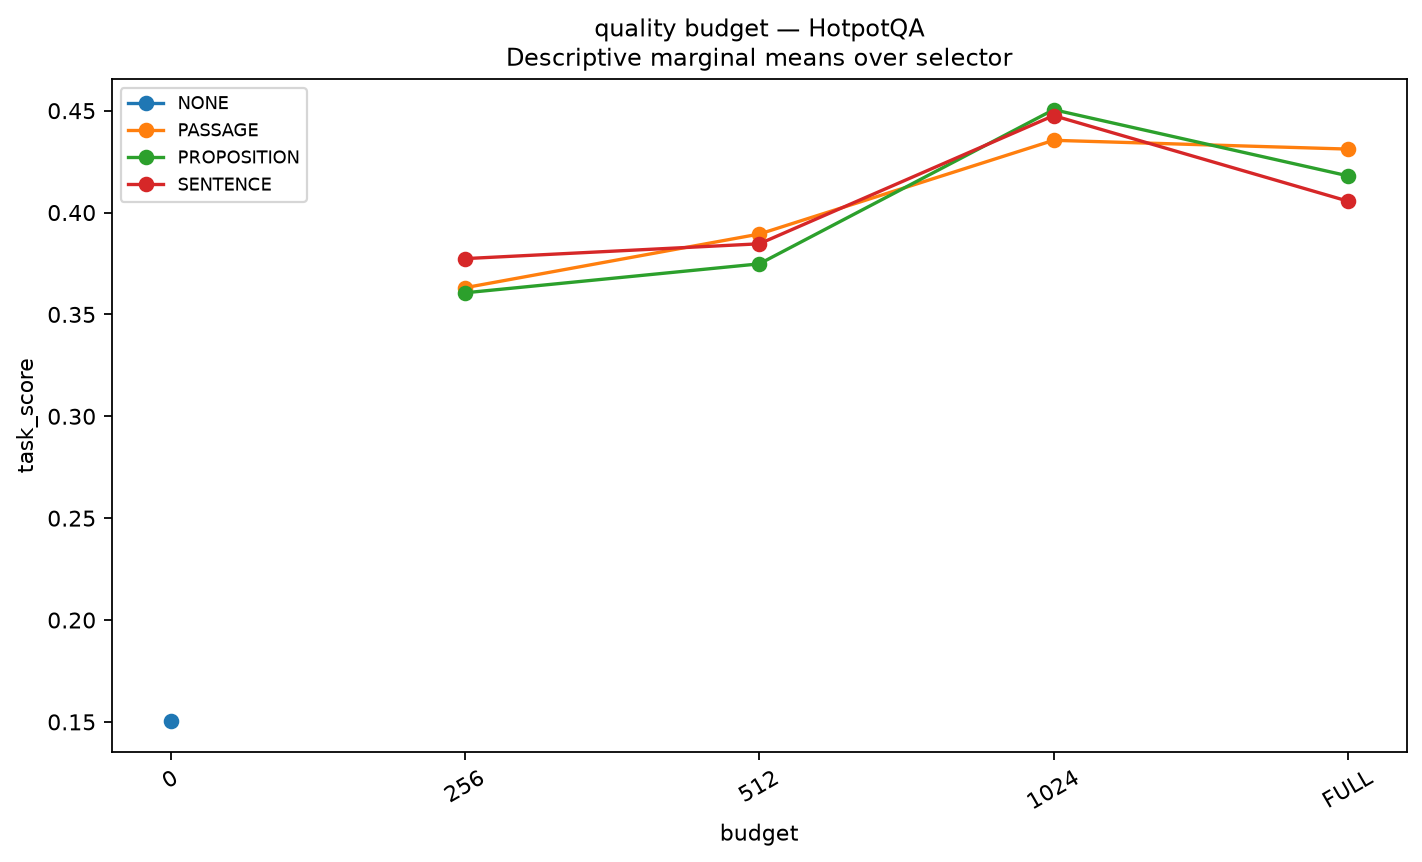

quality_budget QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


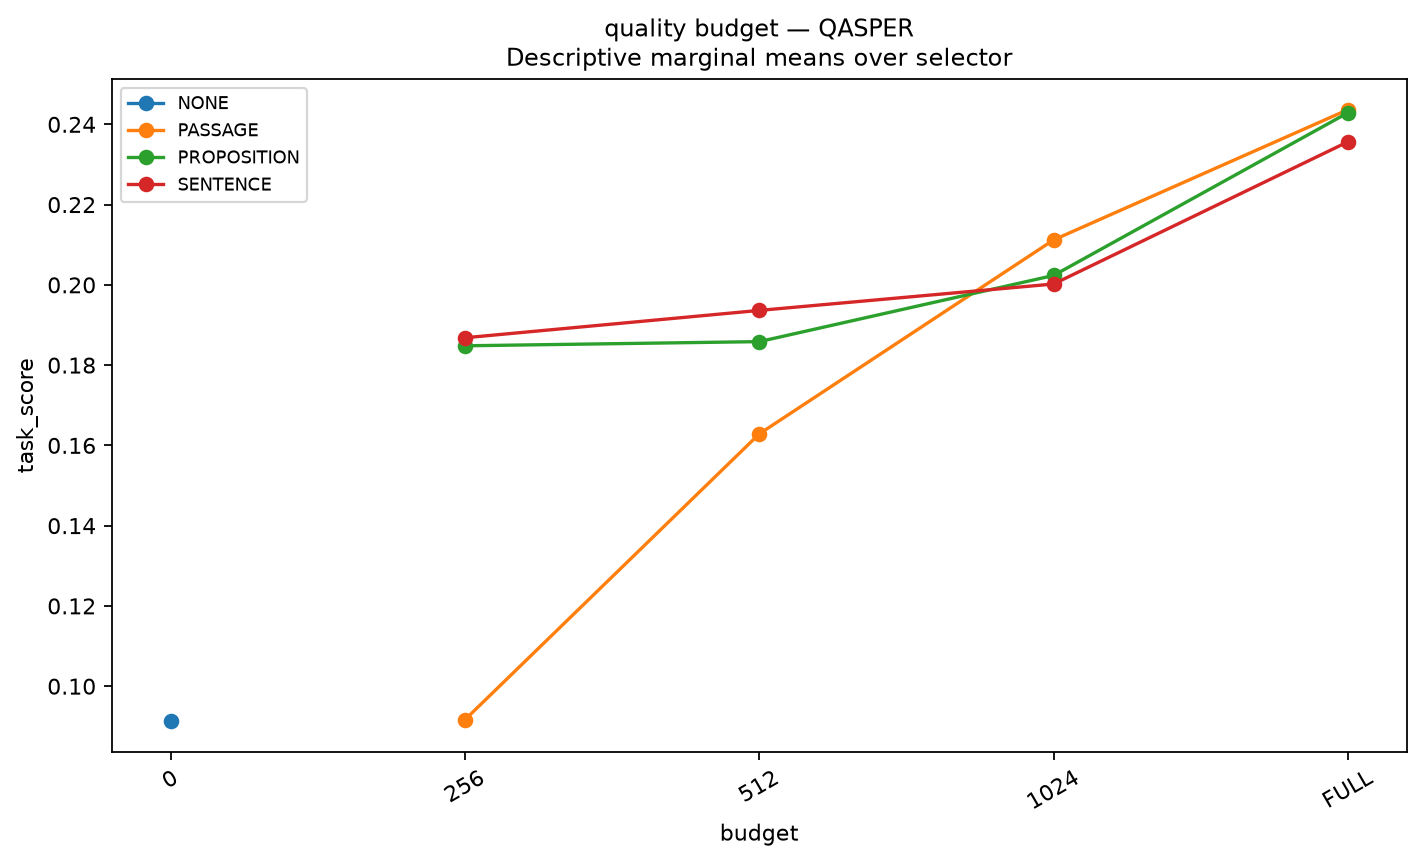

quality_budget SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


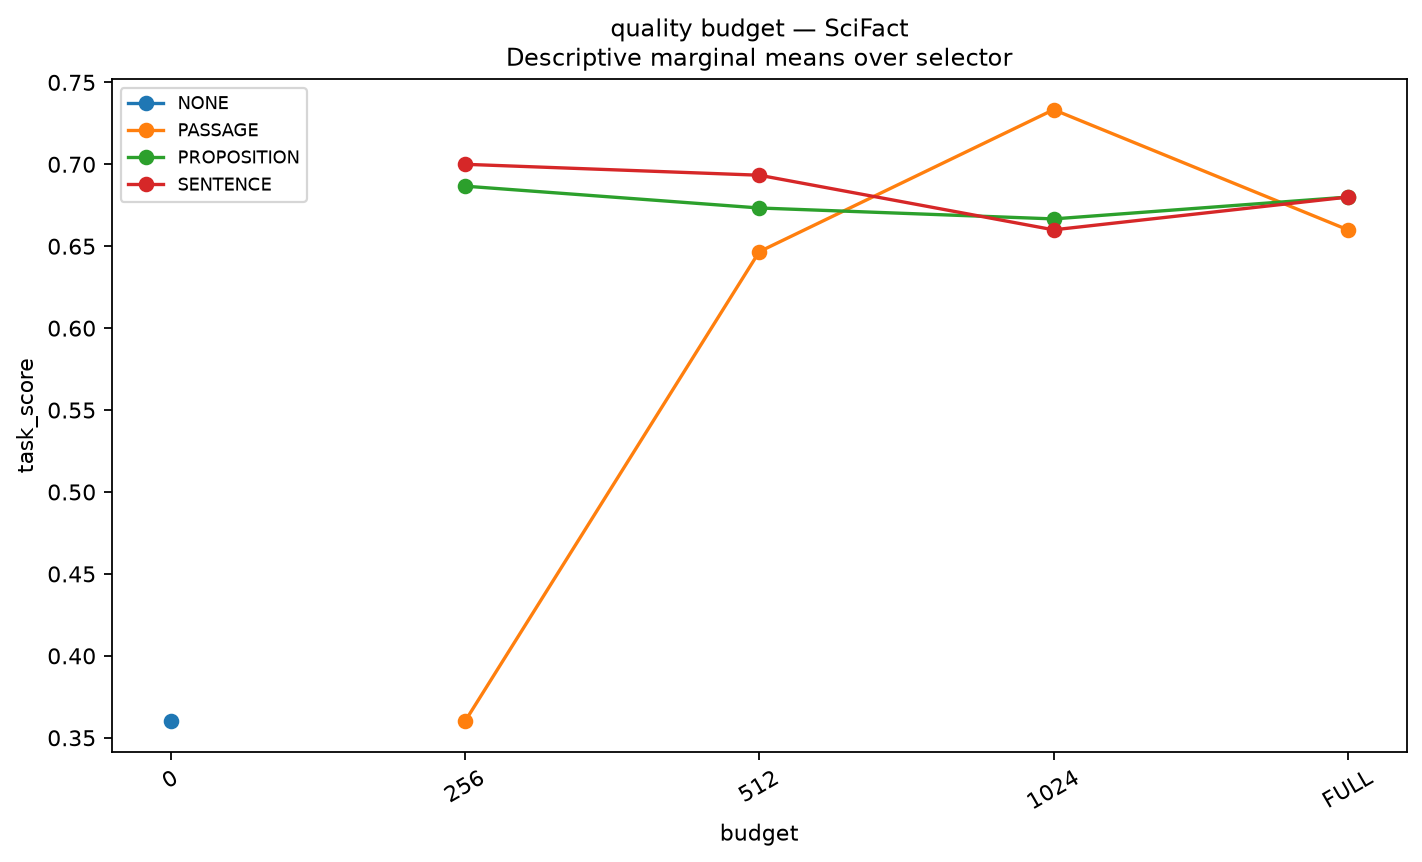

quality_evidence HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


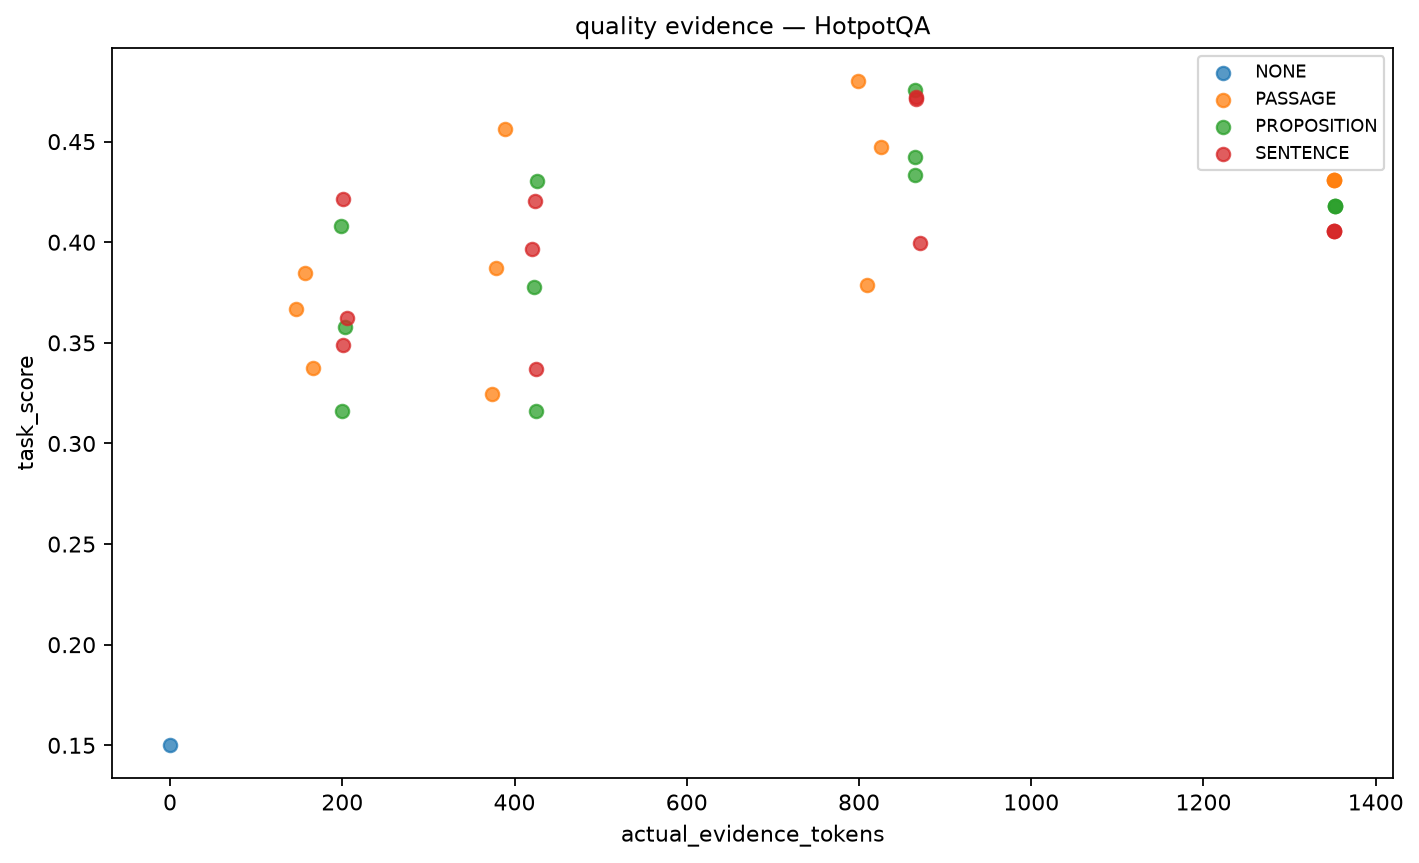

quality_evidence QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


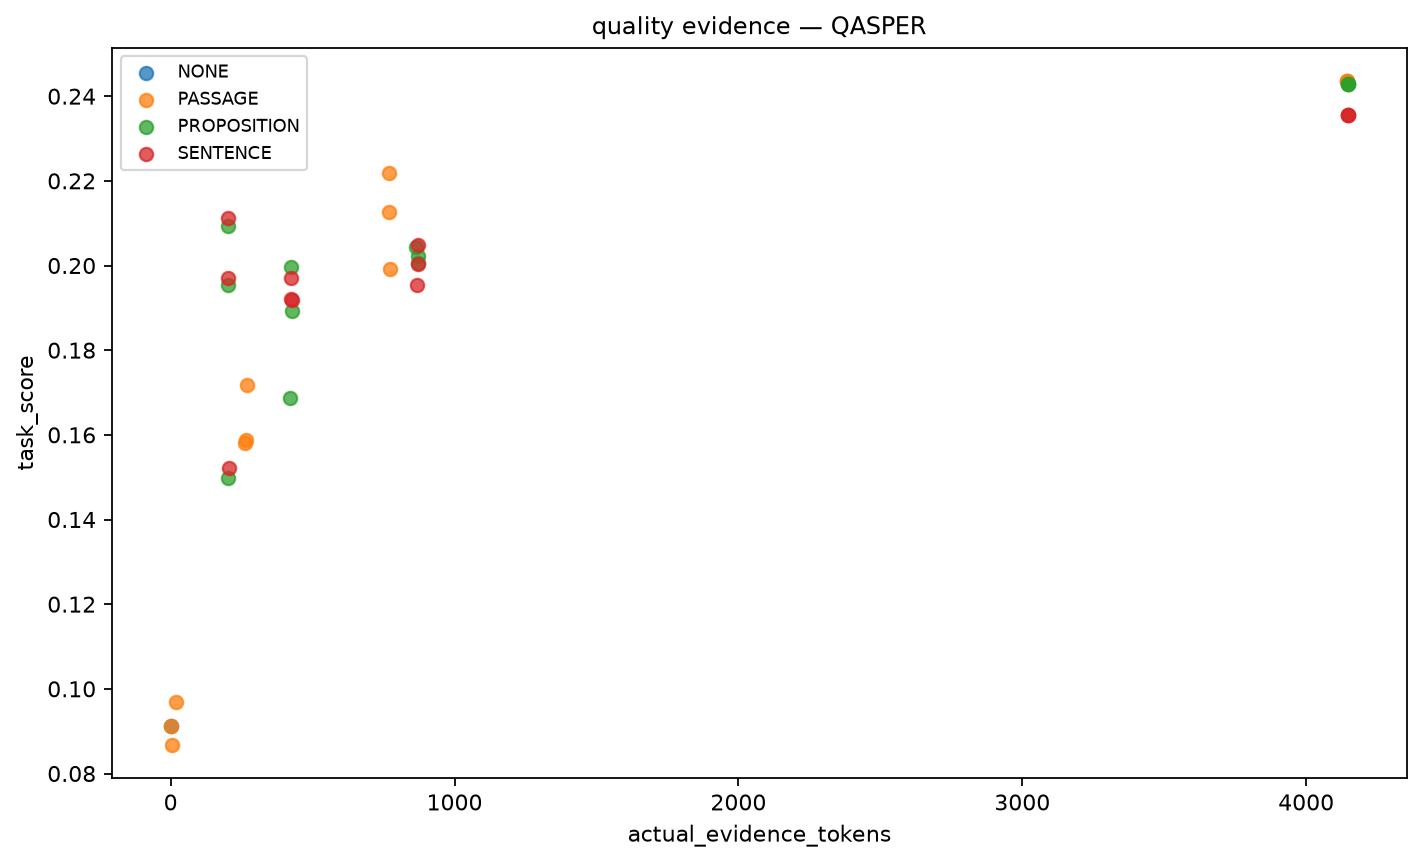

quality_evidence SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


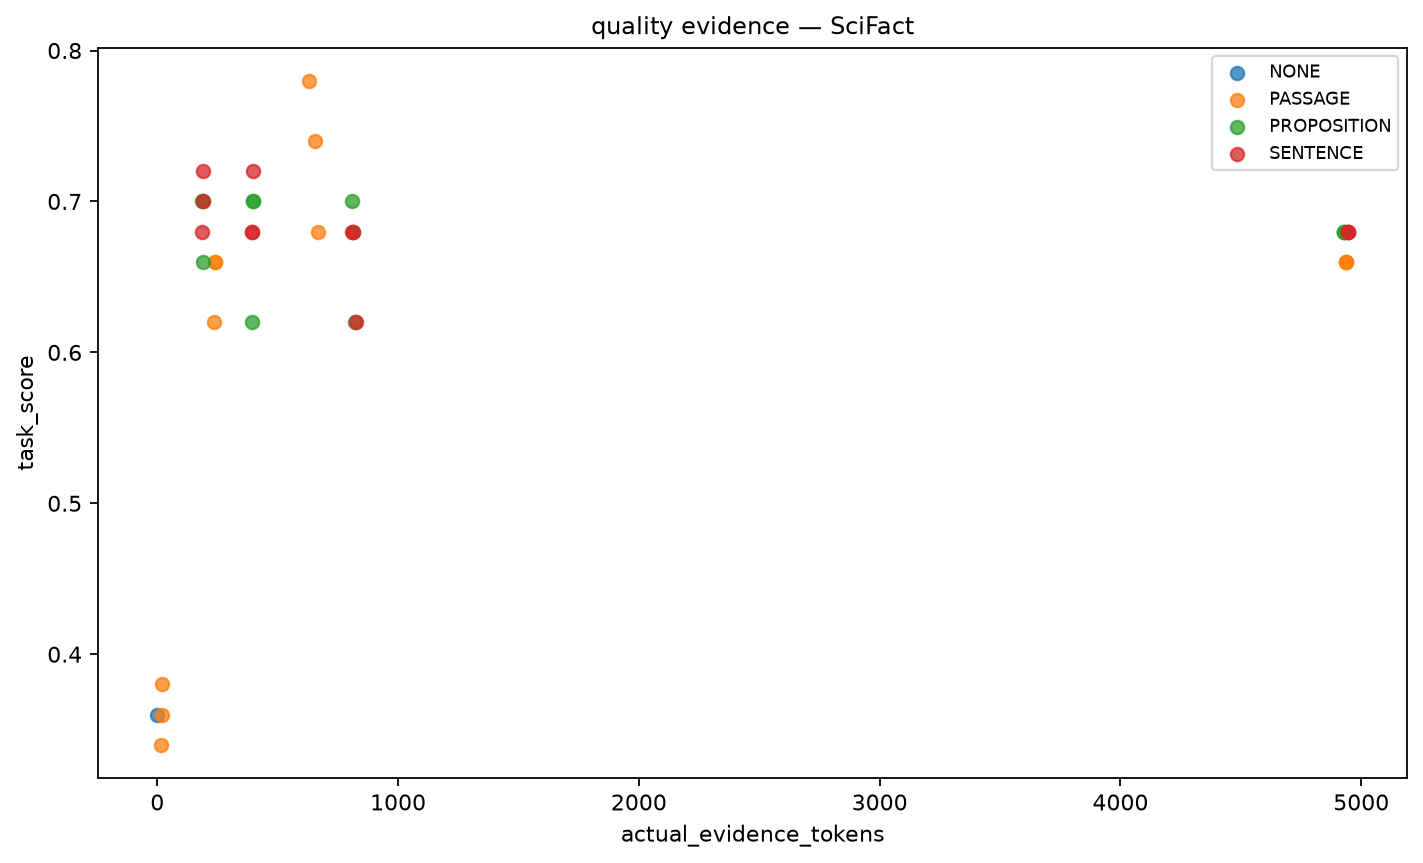

quality_prompt HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


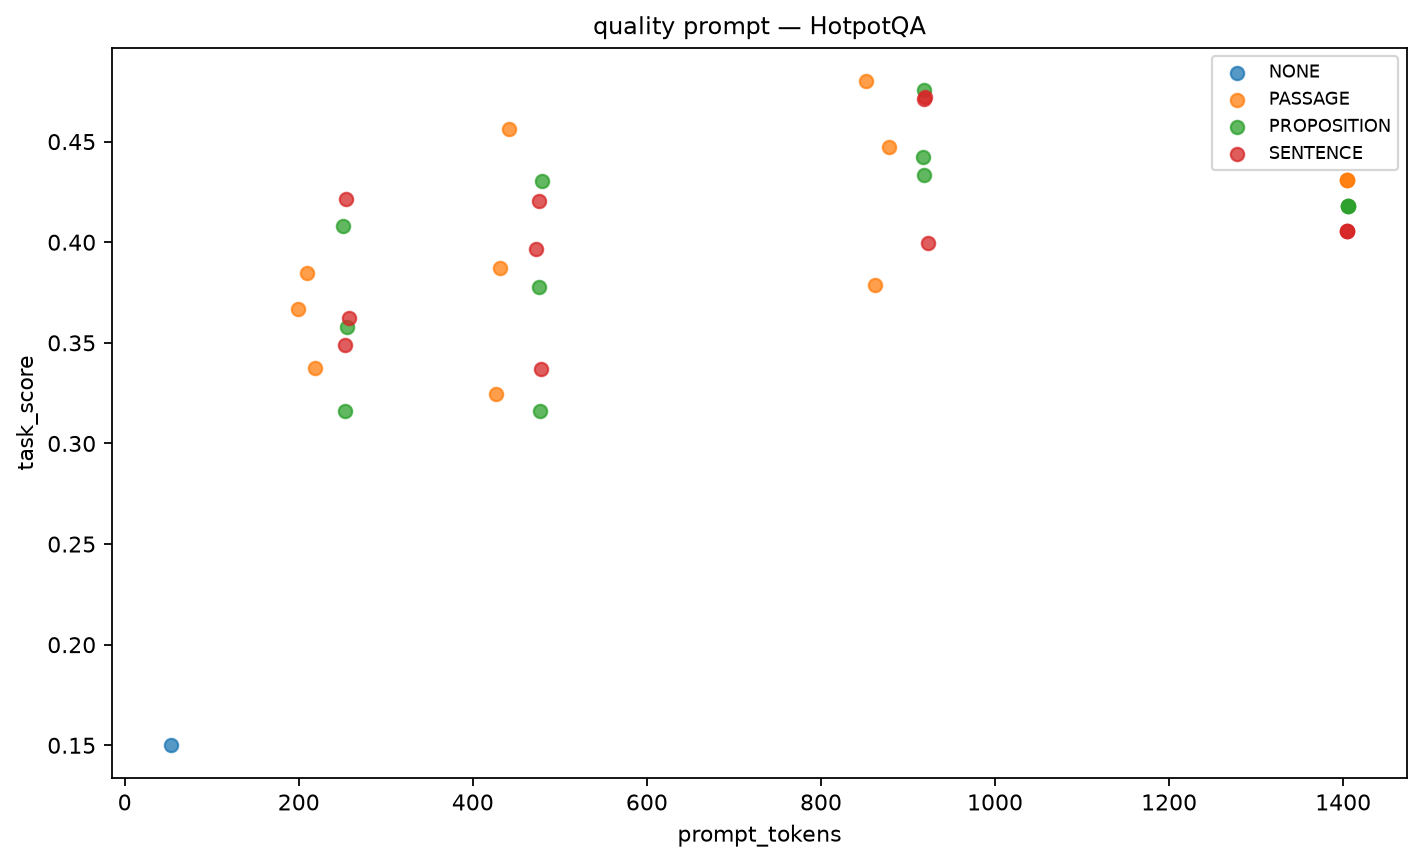

quality_prompt QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


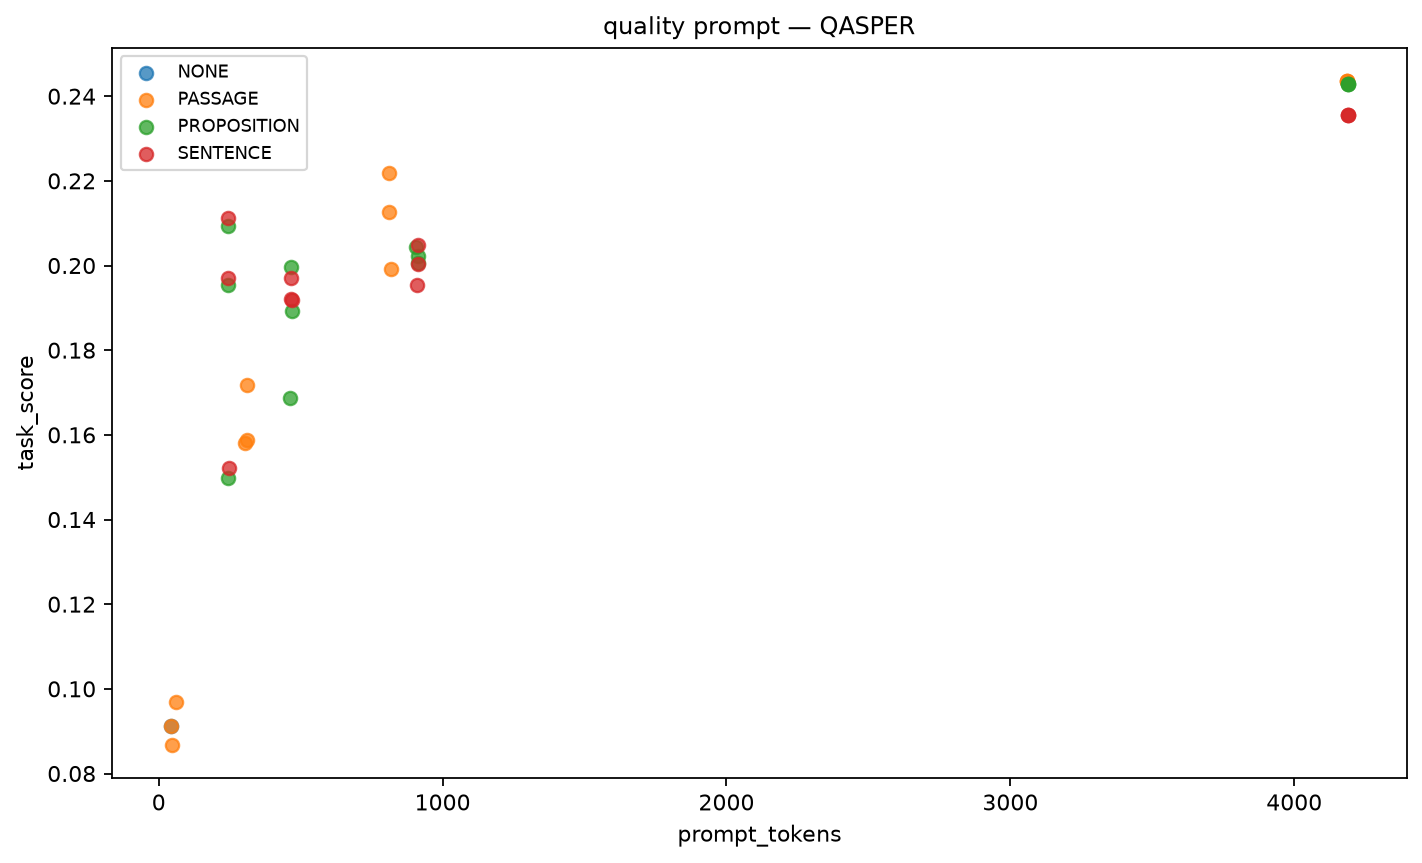

quality_prompt SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


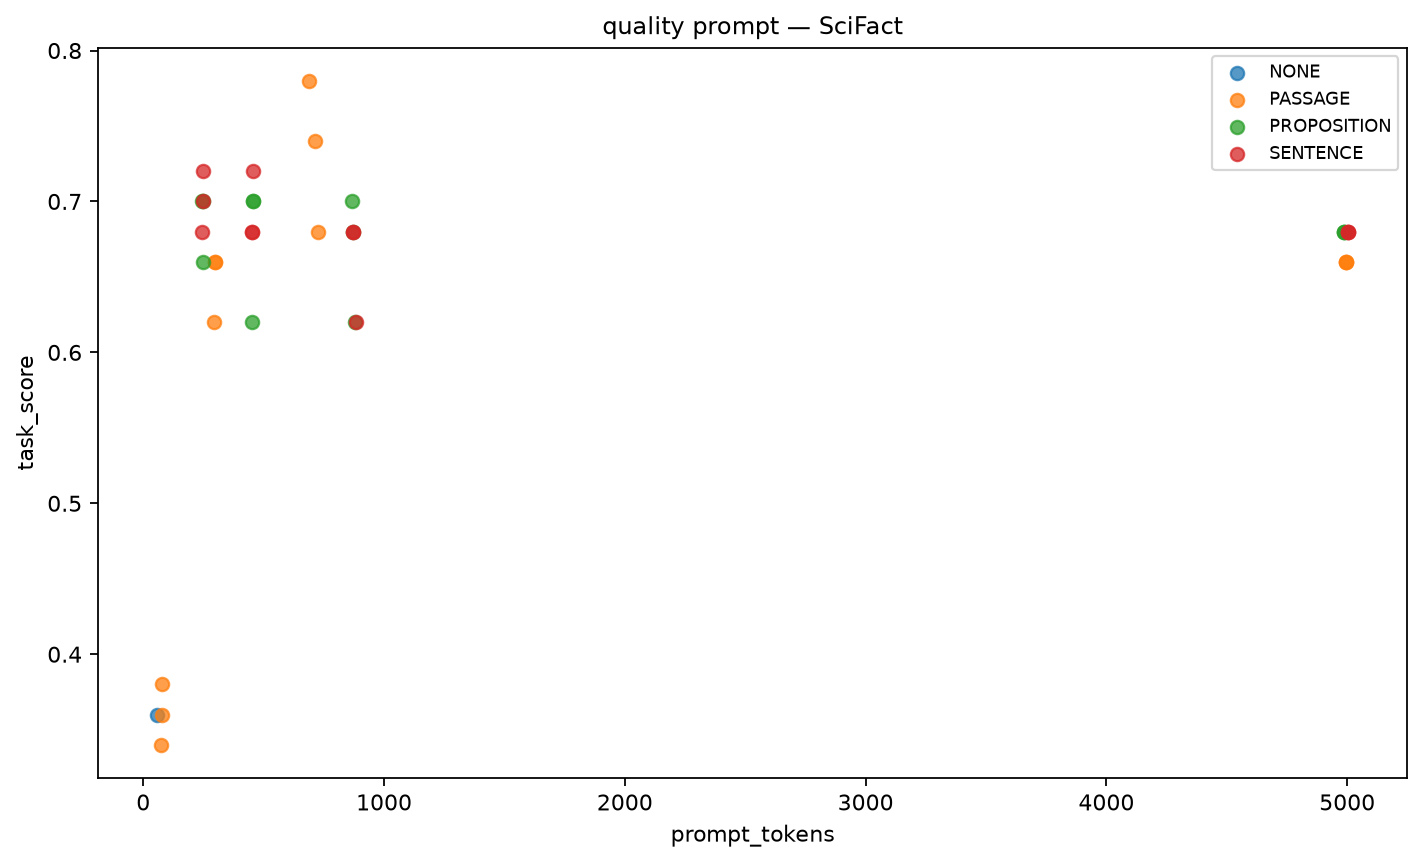

granularity_budget HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


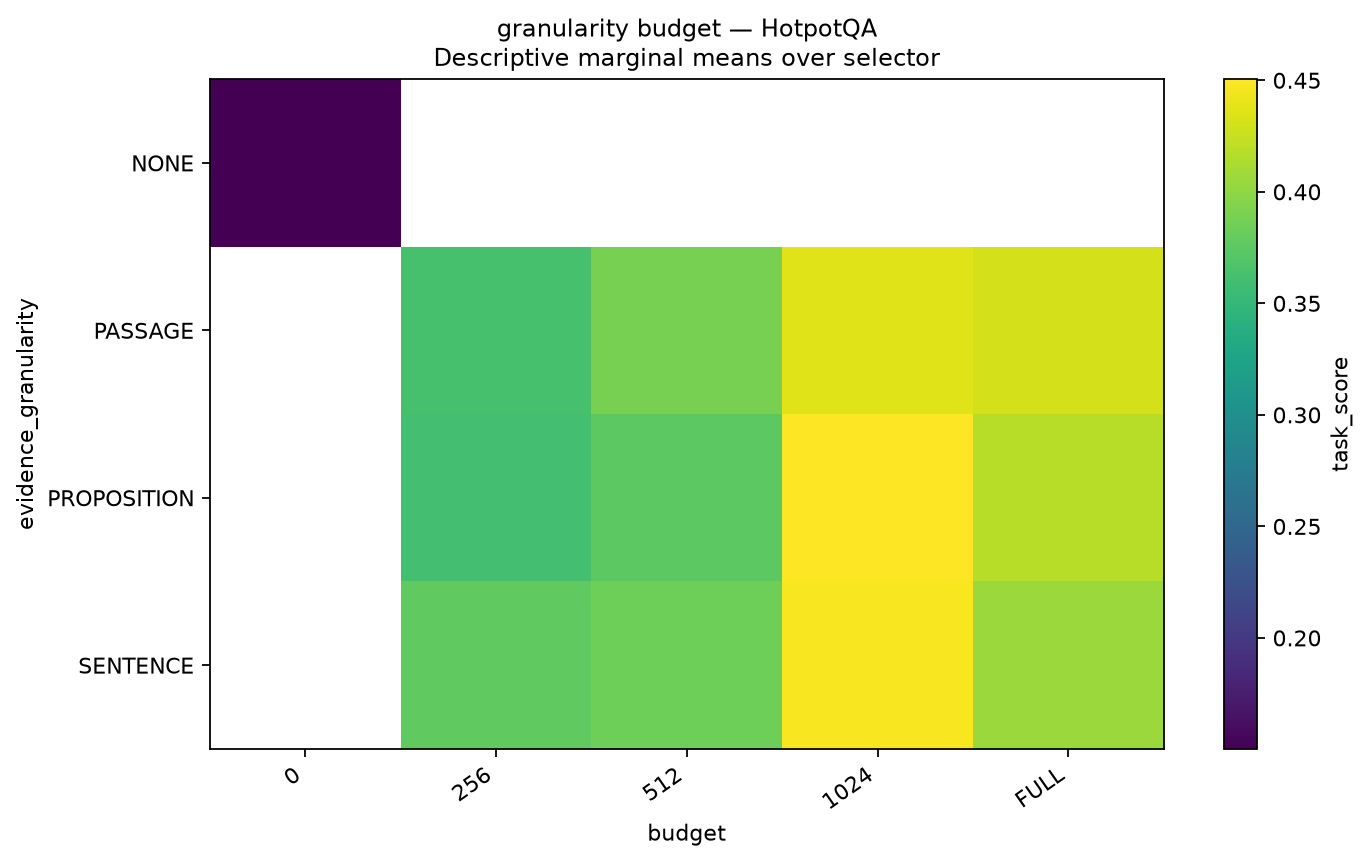

granularity_budget QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


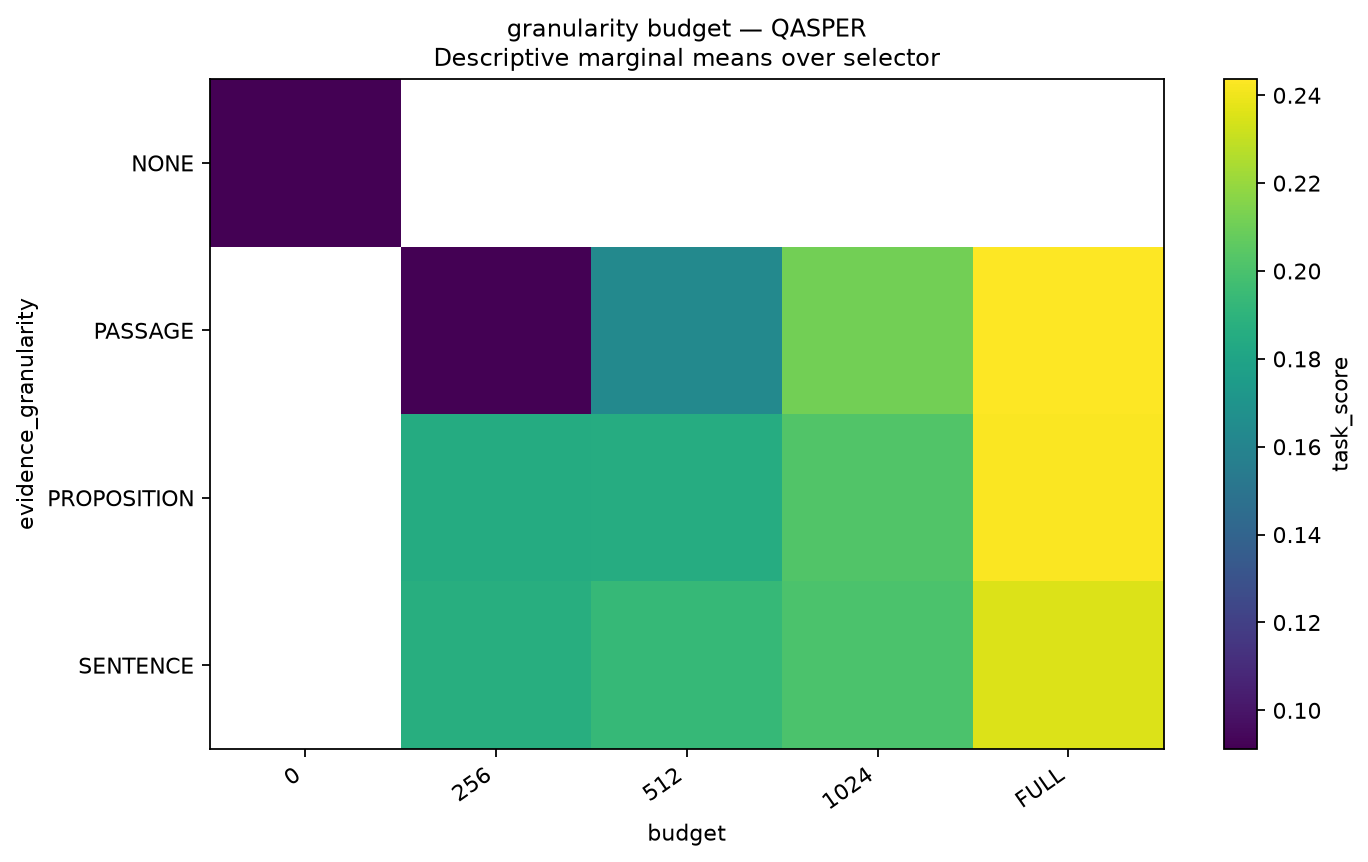

granularity_budget SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


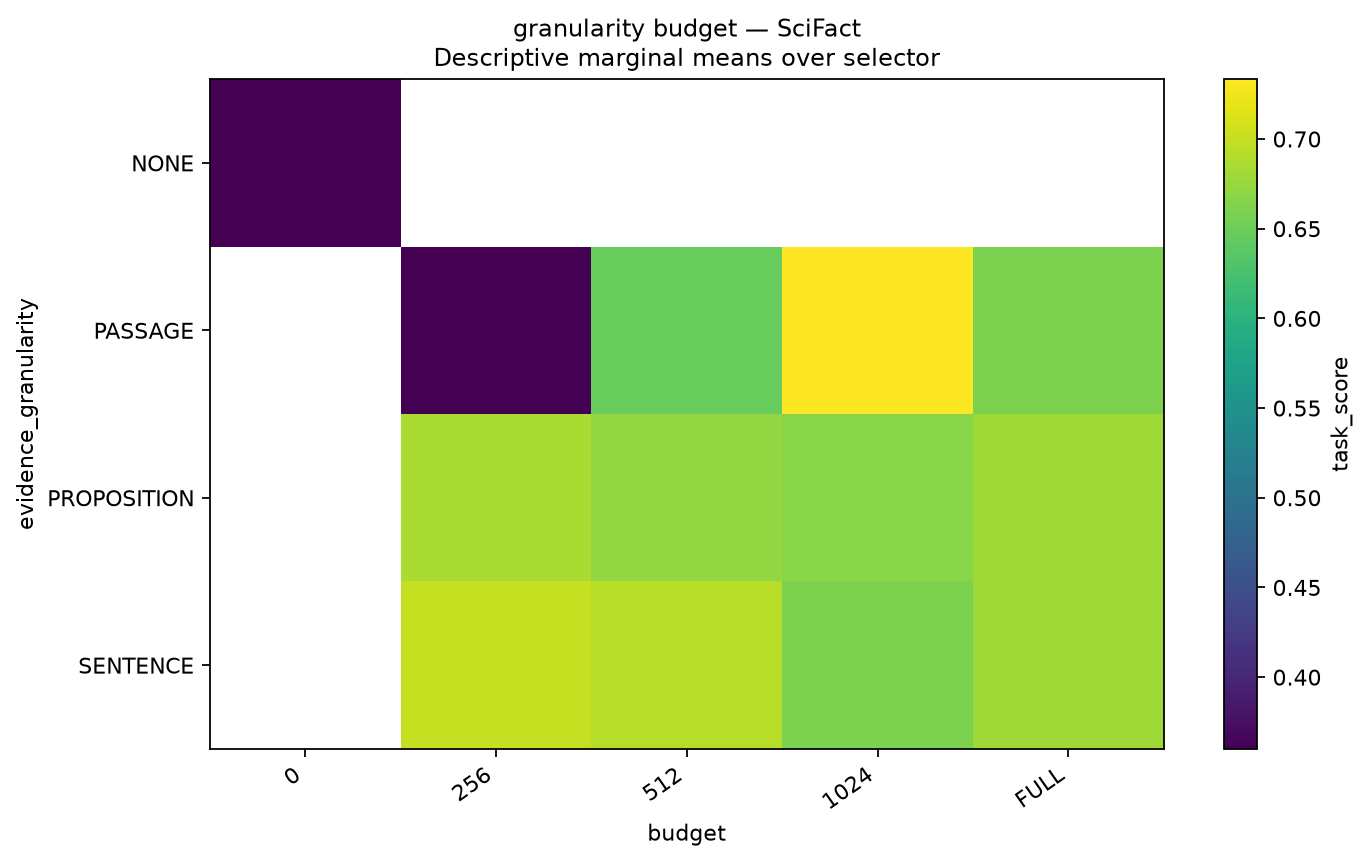

granularity_selector HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


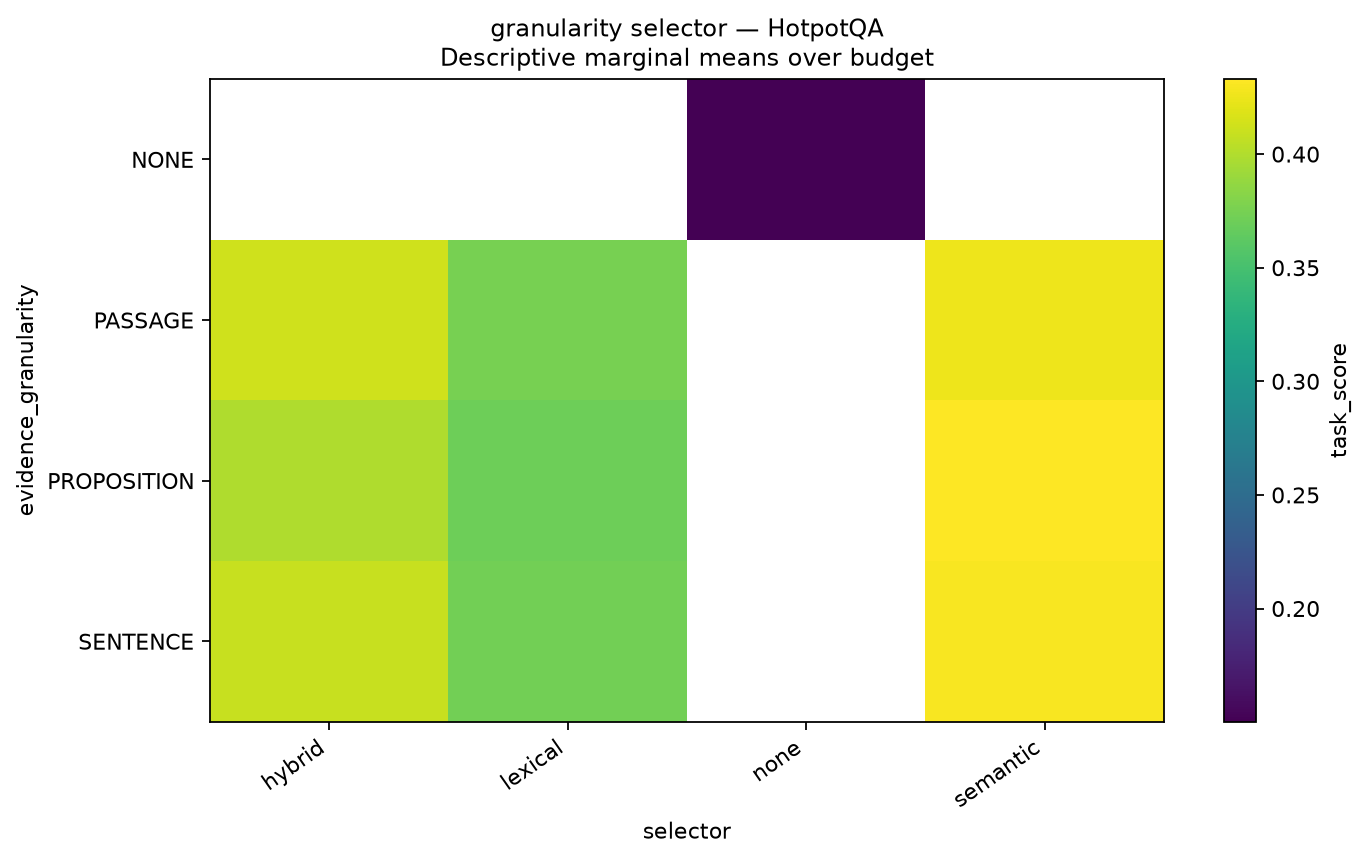

granularity_selector QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


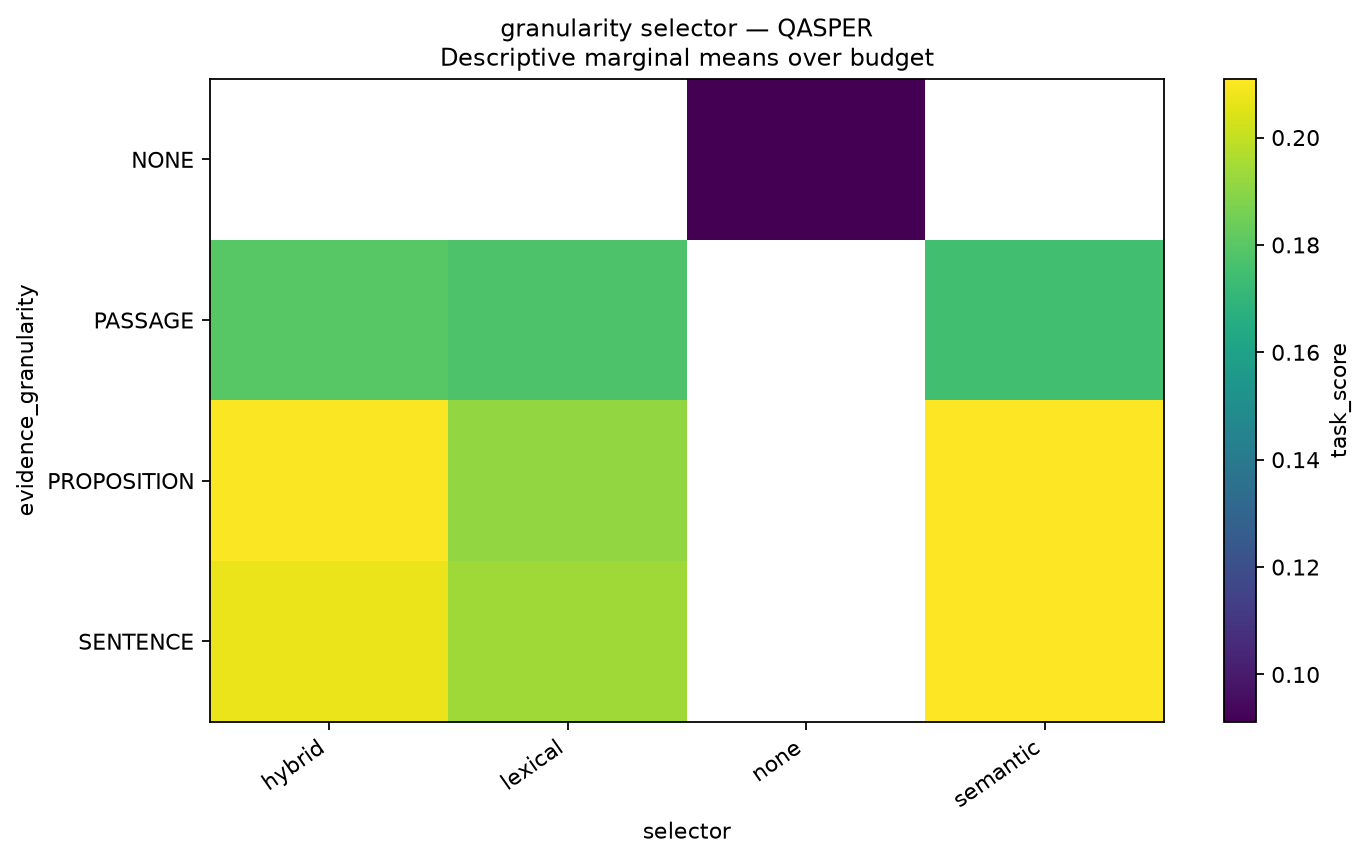

granularity_selector SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


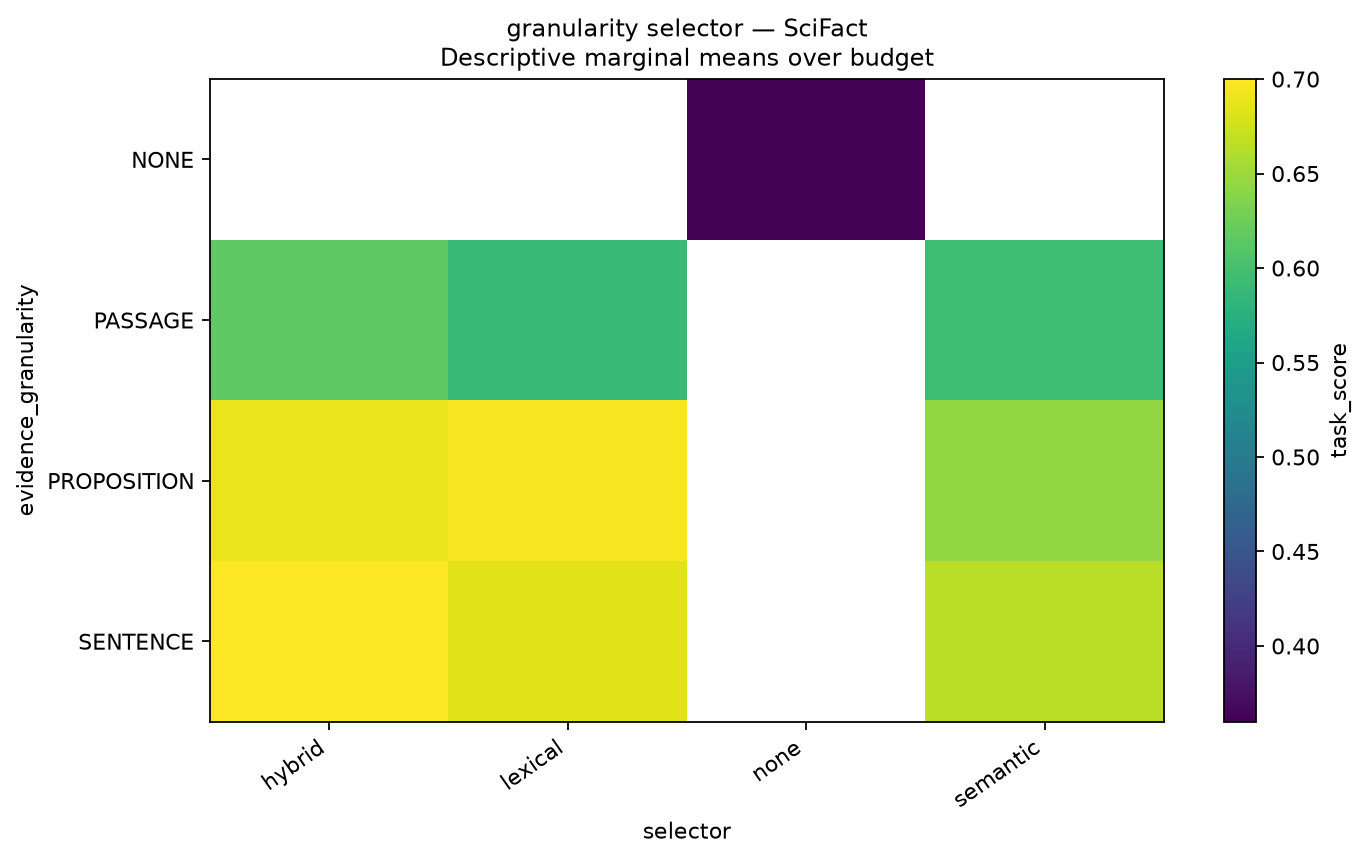

help_hurt HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


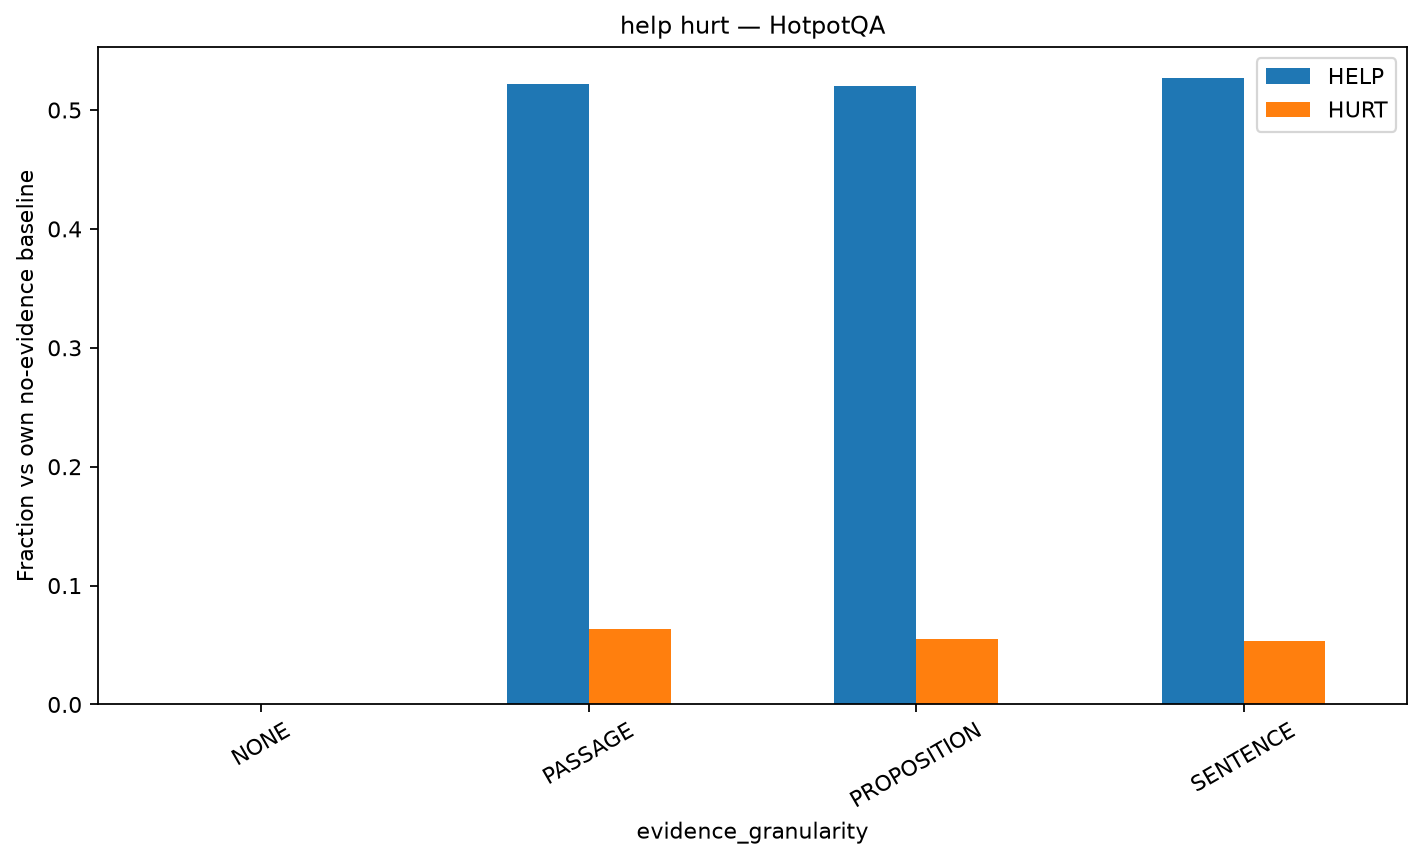

help_hurt QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


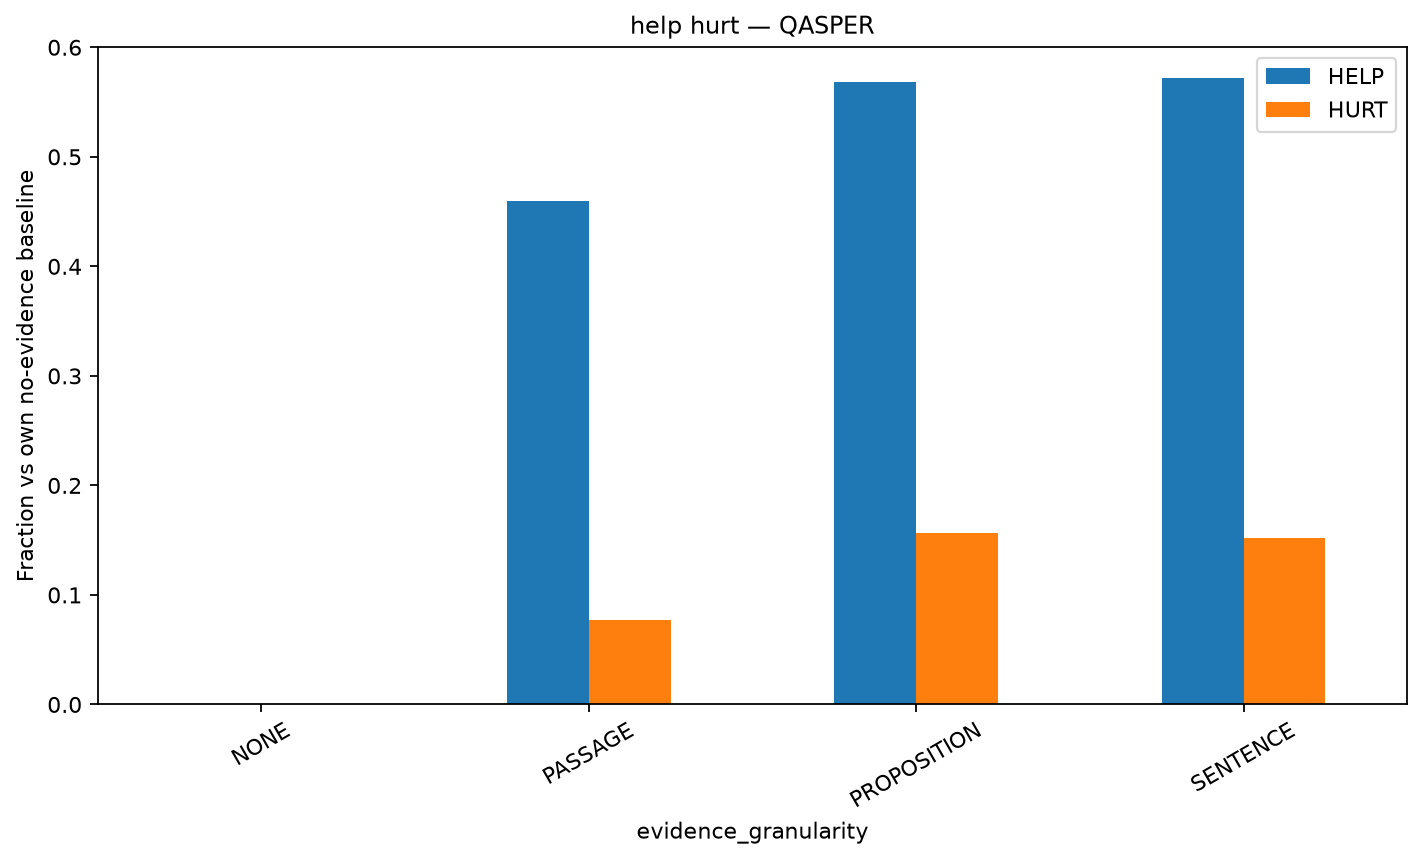

help_hurt SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


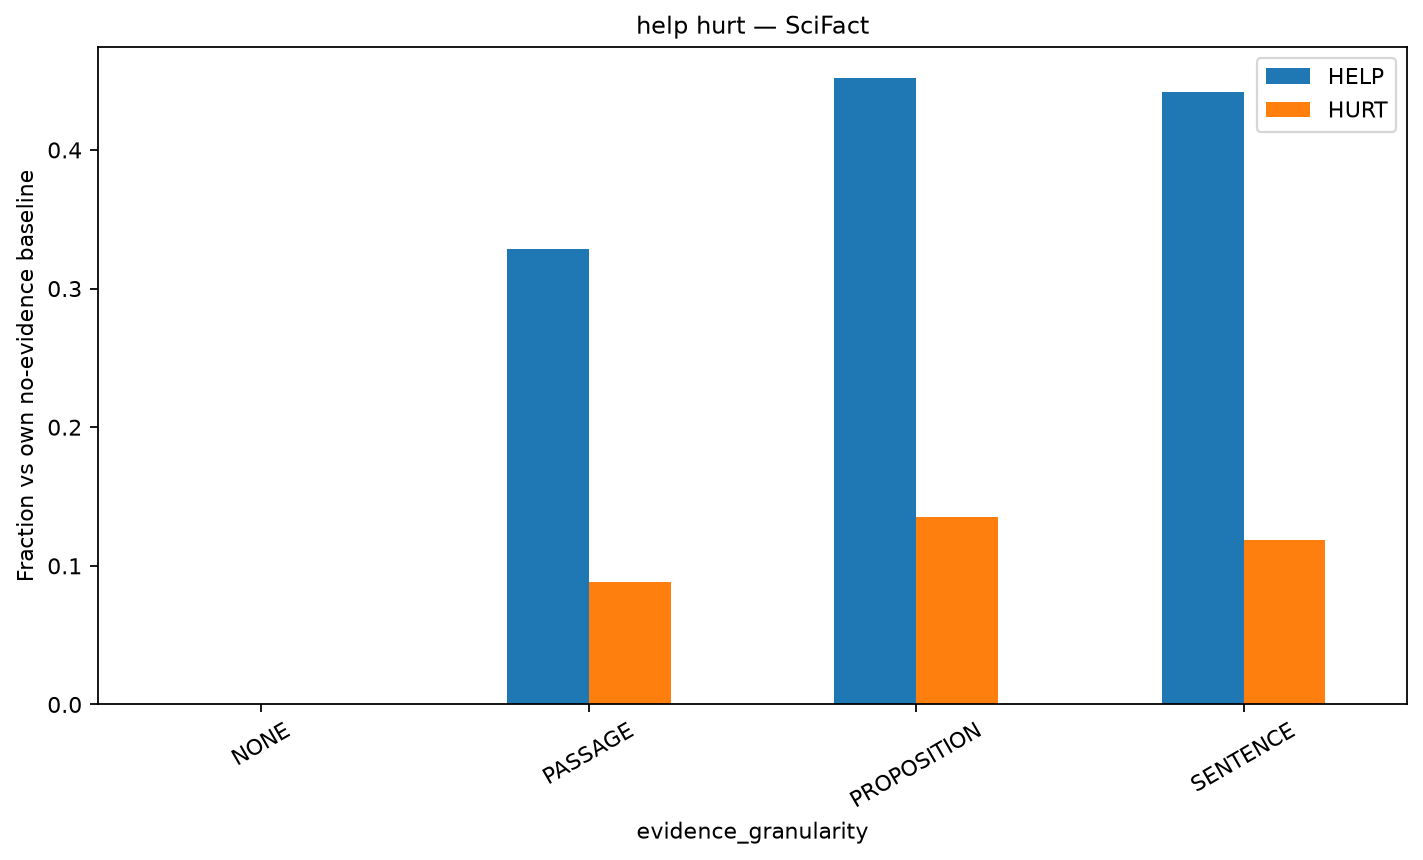

pareto HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate,pareto
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN,True
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN,False
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN,False
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN,False
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN,True
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN,False
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN,True
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN,False
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN,True
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN,True


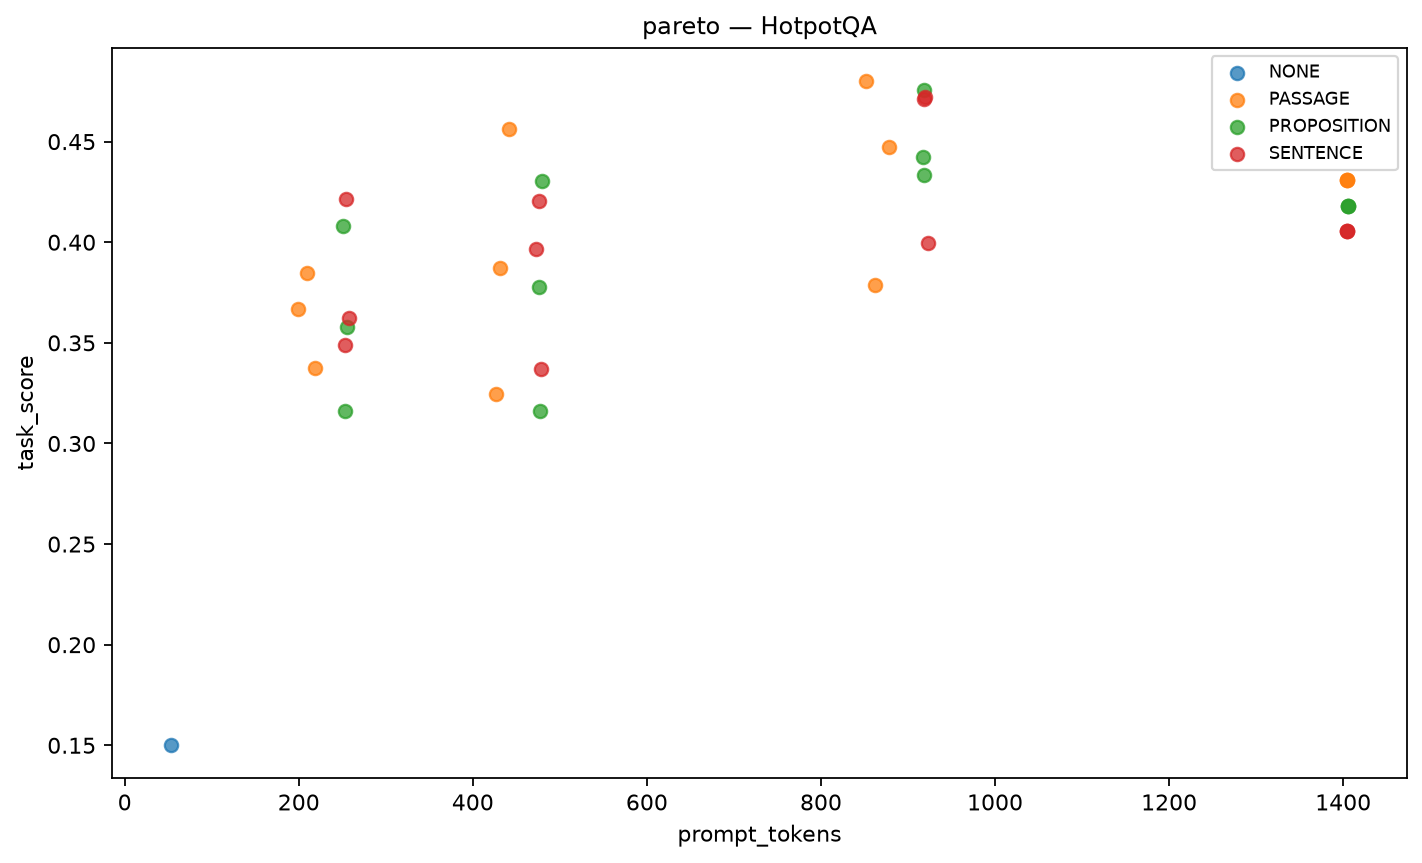

pareto QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate,pareto
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN,False
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN,False
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN,True
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN,False
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN,True
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN,True
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN,True
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN,False
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN,False
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN,True


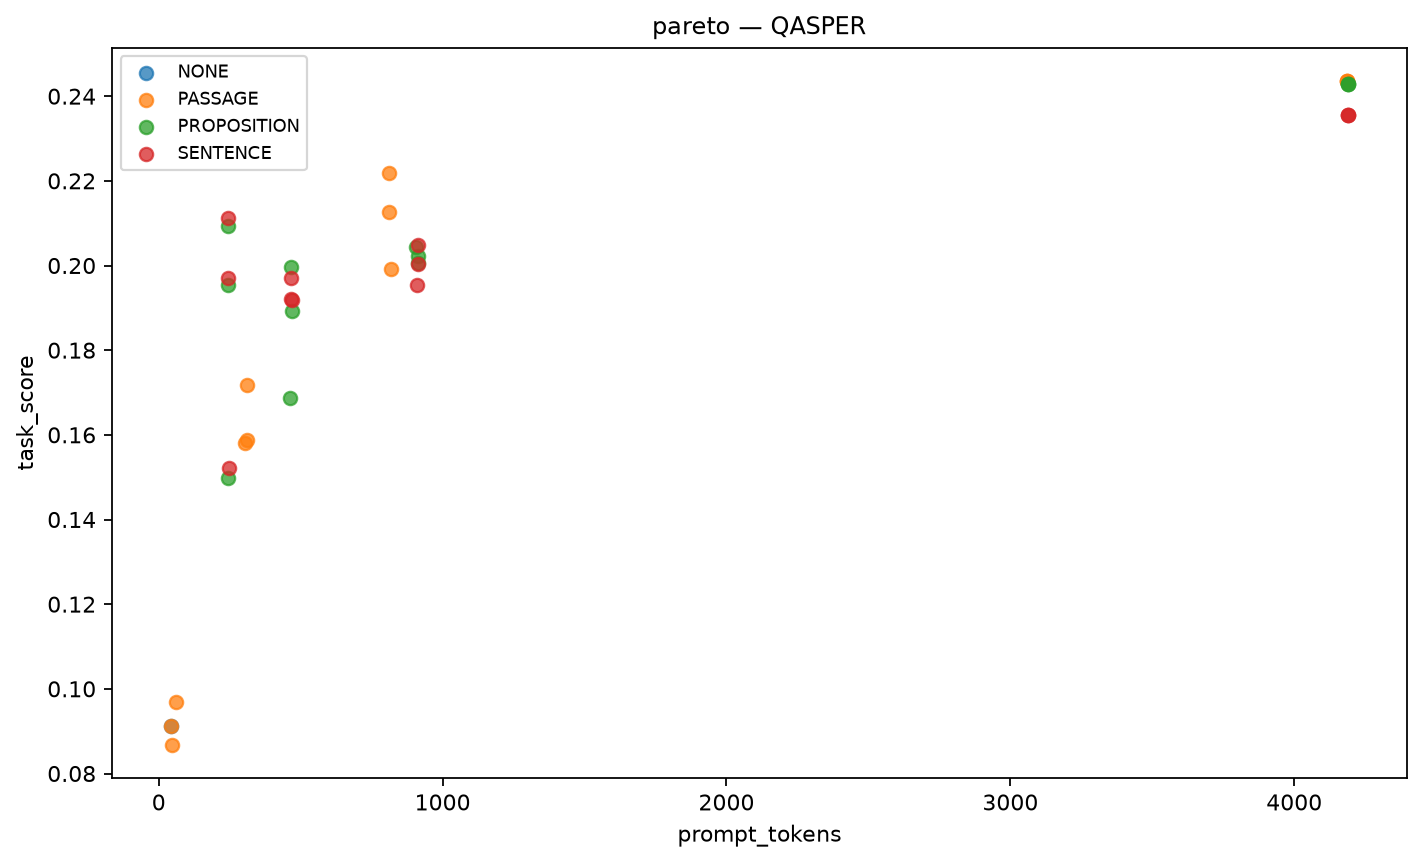

pareto SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate,pareto
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0,False
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0,False
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0,False
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0,False
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0,True
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0,False
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0,False
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0,False
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0,False
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0,False


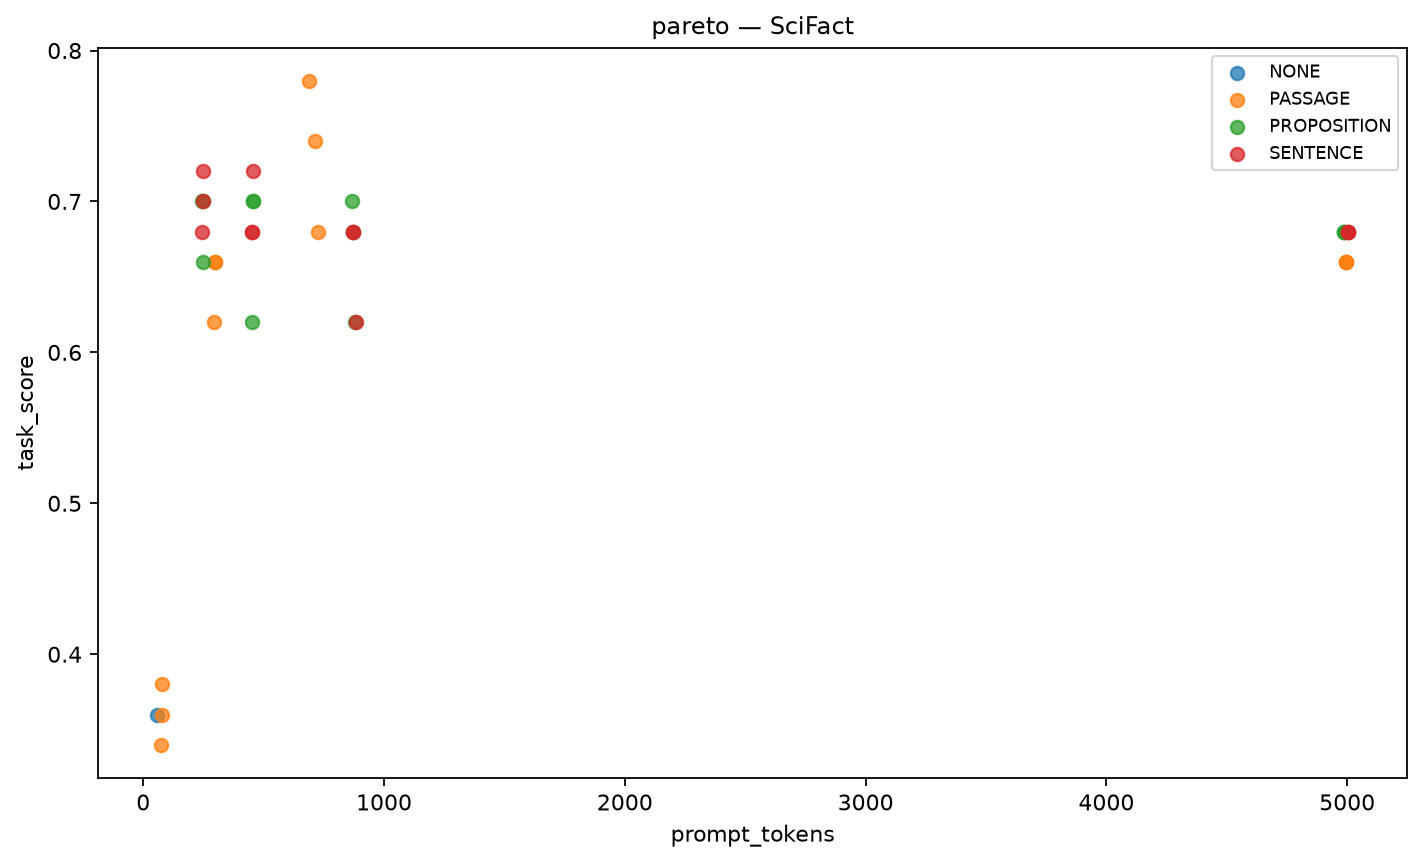

quality_per_1000 HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


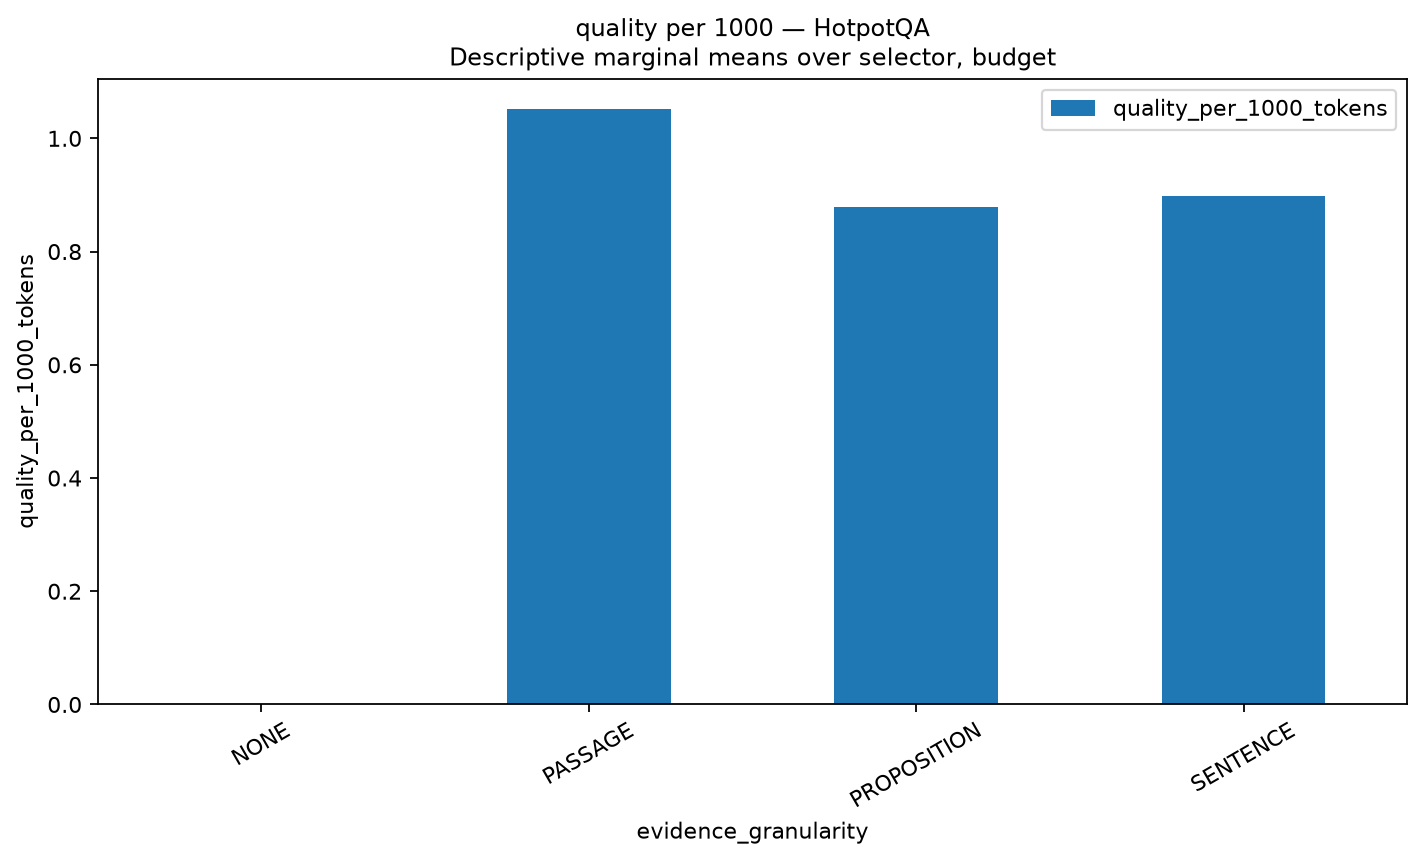

quality_per_1000 QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


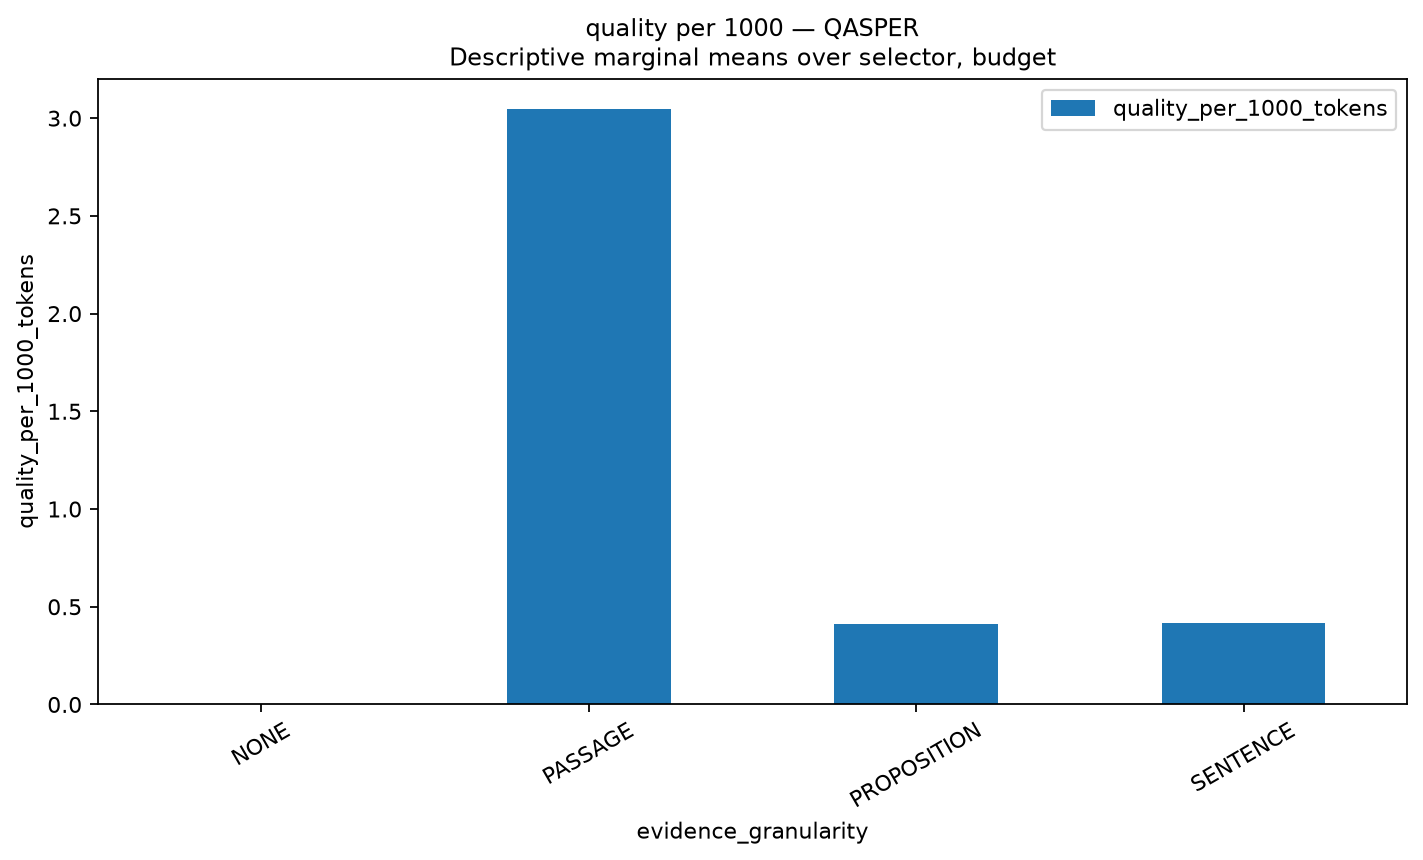

quality_per_1000 SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


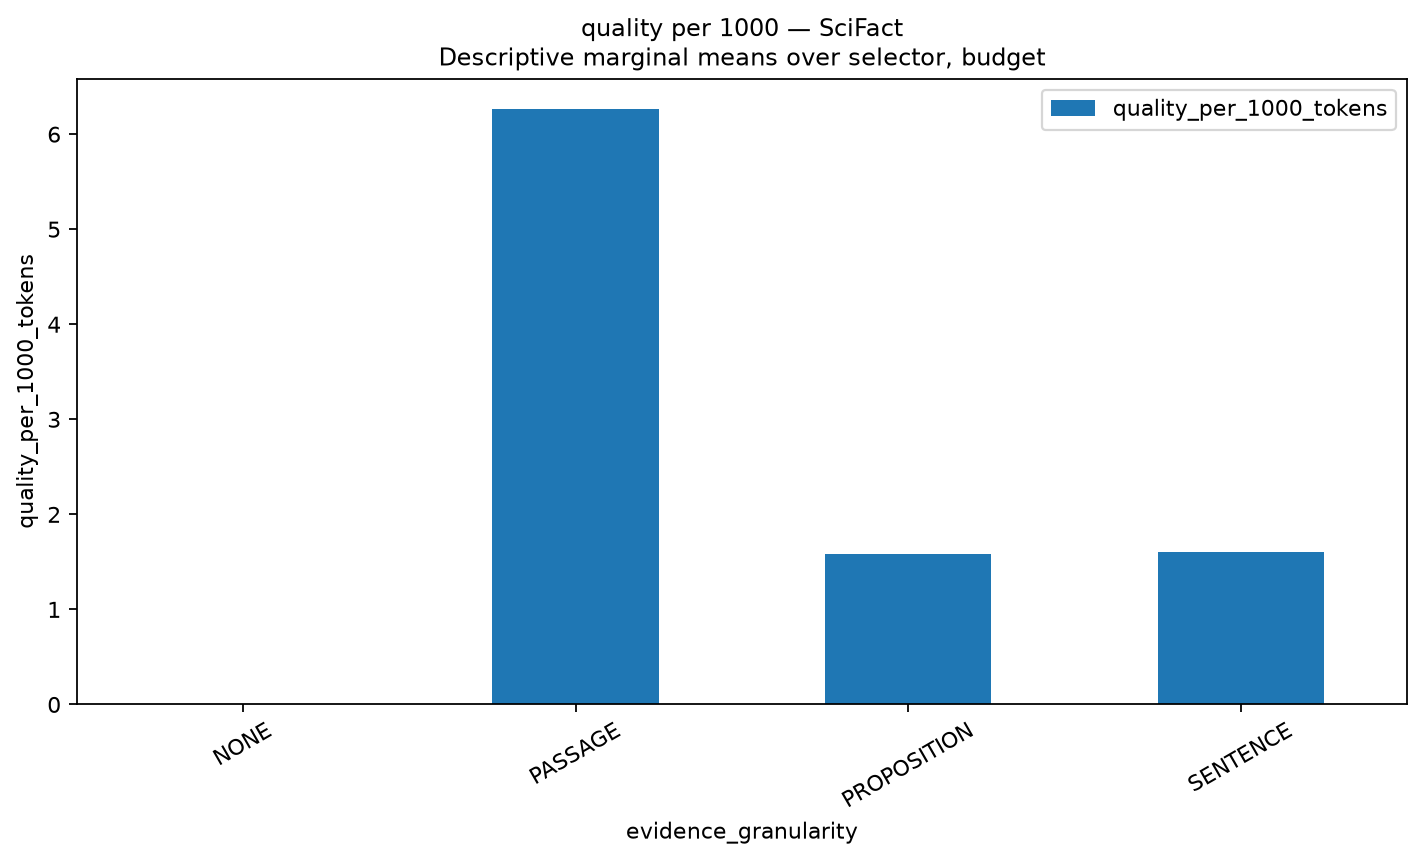

actual_requested HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


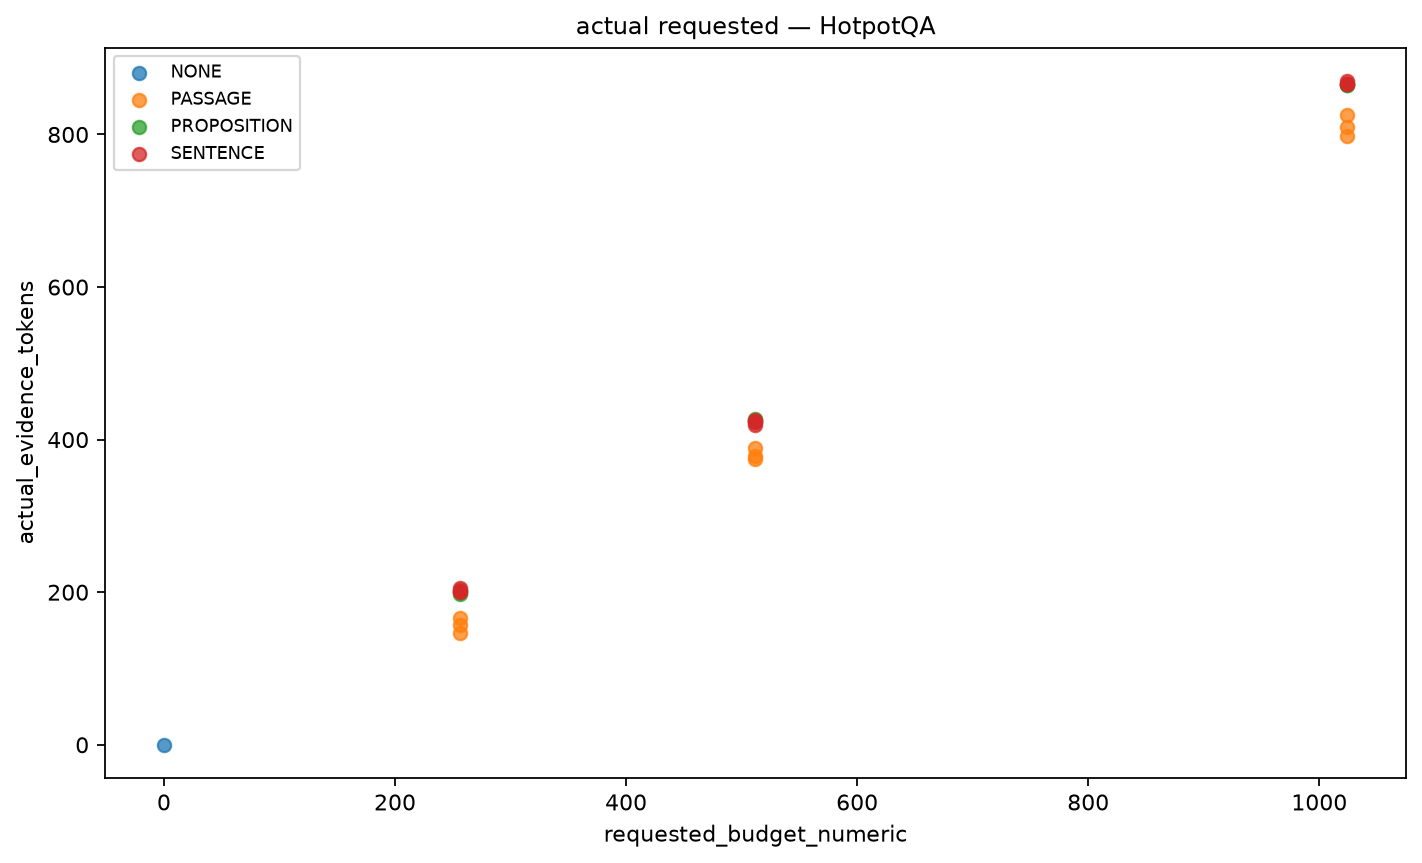

actual_requested QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


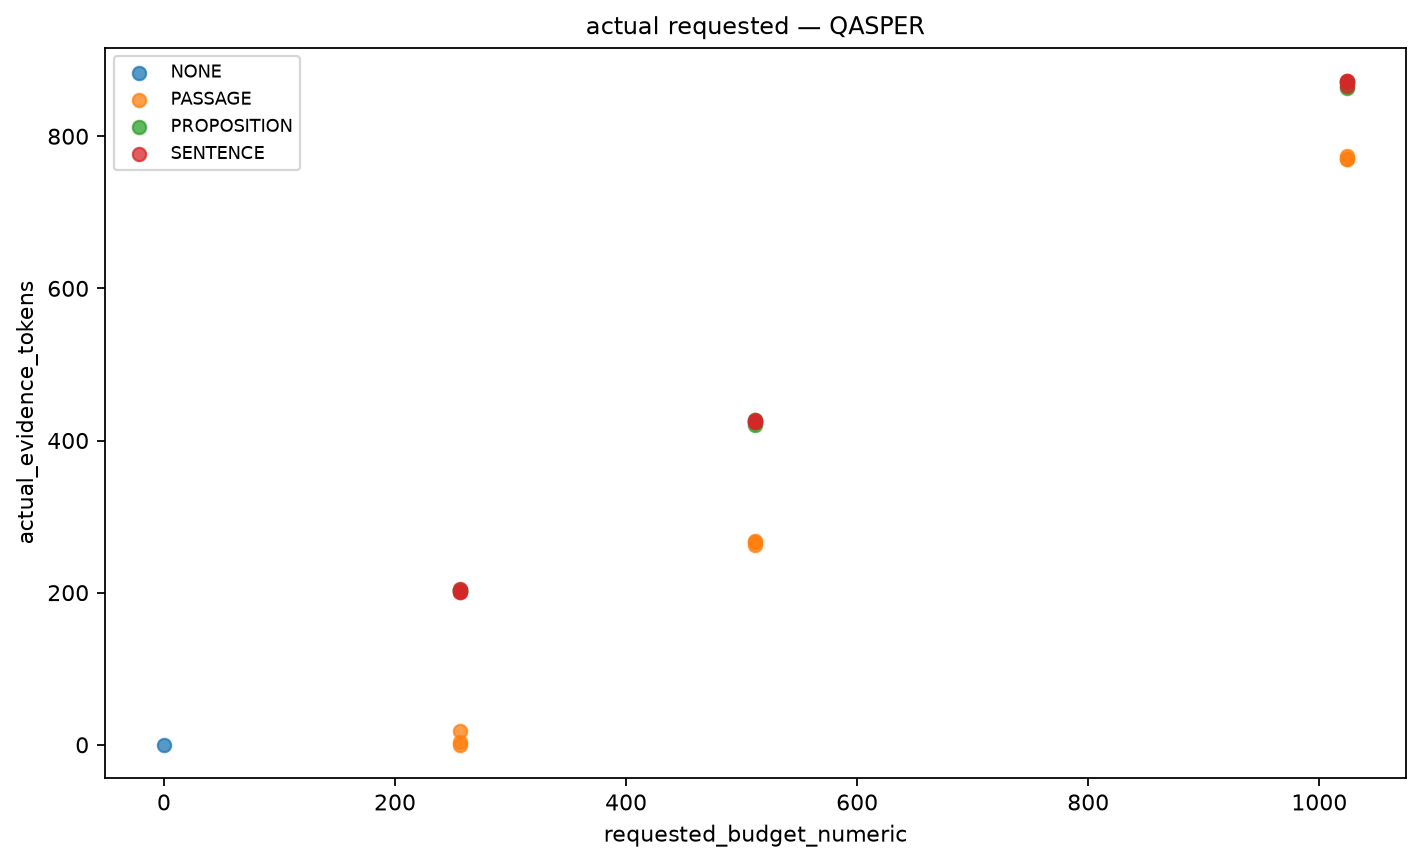

actual_requested SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


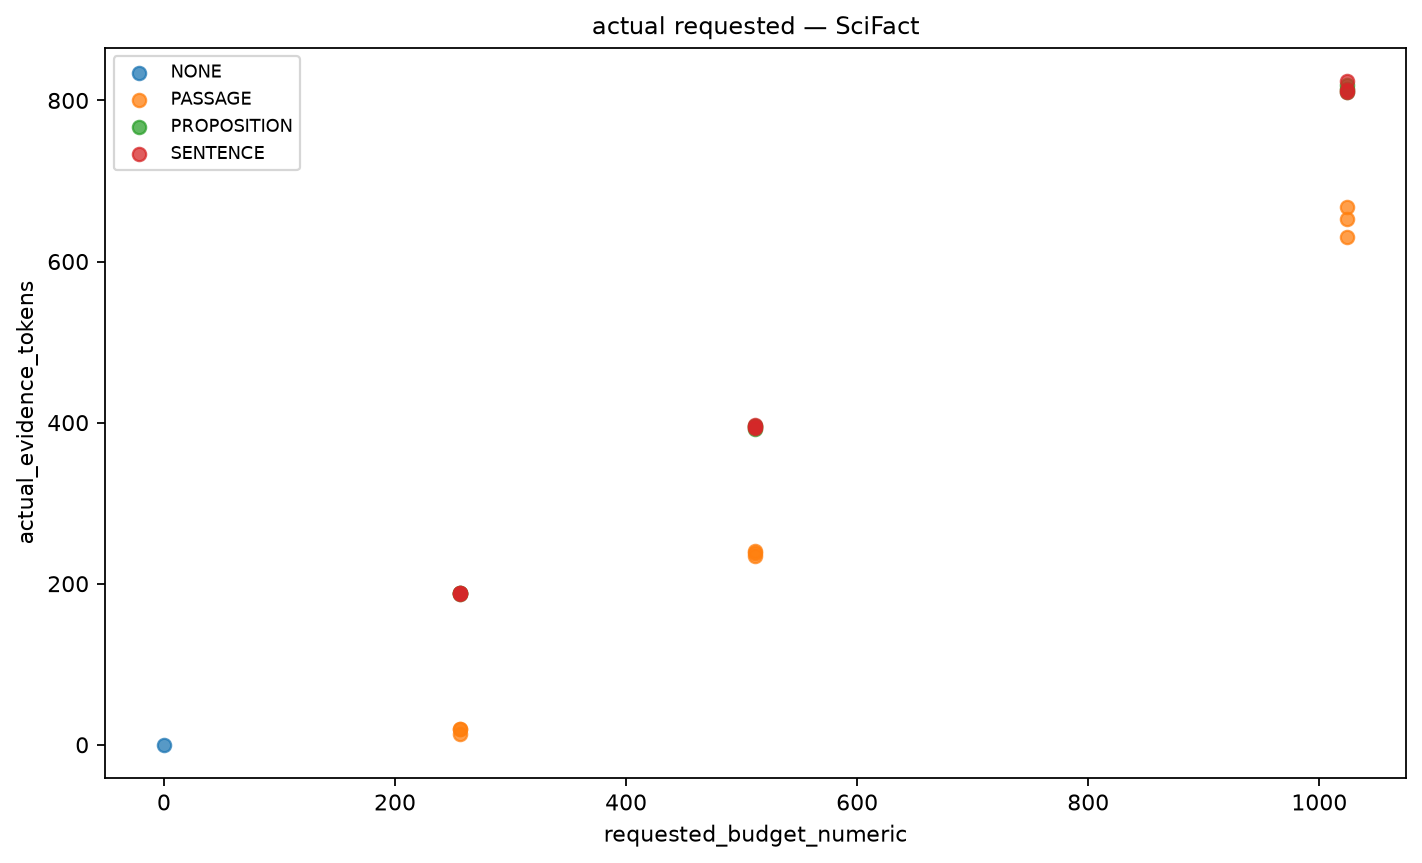

dataset_quality HotpotQA


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,HotpotQA,multihop_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,0.700167,20.0,0.059504,1.0,0.456280,0.0,122.90,50,1.172654,512.0,NaN,NaN
1,HotpotQA,multihop_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.061982,1.0,0.405590,0.0,NaN,50,0.300210,NaN,NaN,NaN
2,HotpotQA,multihop_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,0.700167,20.0,0.057096,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
3,HotpotQA,multihop_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,0.700167,20.0,0.069321,1.0,0.316340,0.0,87.62,50,0.745417,512.0,NaN,NaN
4,HotpotQA,multihop_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.006317,1.0,0.150250,0.0,0.00,50,NaN,0.0,NaN,NaN
5,HotpotQA,multihop_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,0.700167,20.0,0.053846,1.0,0.431145,0.0,NaN,50,0.319116,NaN,NaN,NaN
6,HotpotQA,multihop_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,0.700167,20.0,0.062250,1.0,0.421265,0.0,54.84,50,2.094177,256.0,NaN,NaN
7,HotpotQA,multihop_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,0.700167,20.0,0.081130,1.0,0.430585,0.0,85.34,50,1.009198,512.0,NaN,NaN
8,HotpotQA,multihop_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,0.700167,20.0,0.062847,1.0,0.407943,0.0,57.70,50,2.057204,256.0,NaN,NaN
9,HotpotQA,multihop_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,0.700167,20.0,0.053351,1.0,0.384781,0.0,98.80,50,2.447716,256.0,NaN,NaN


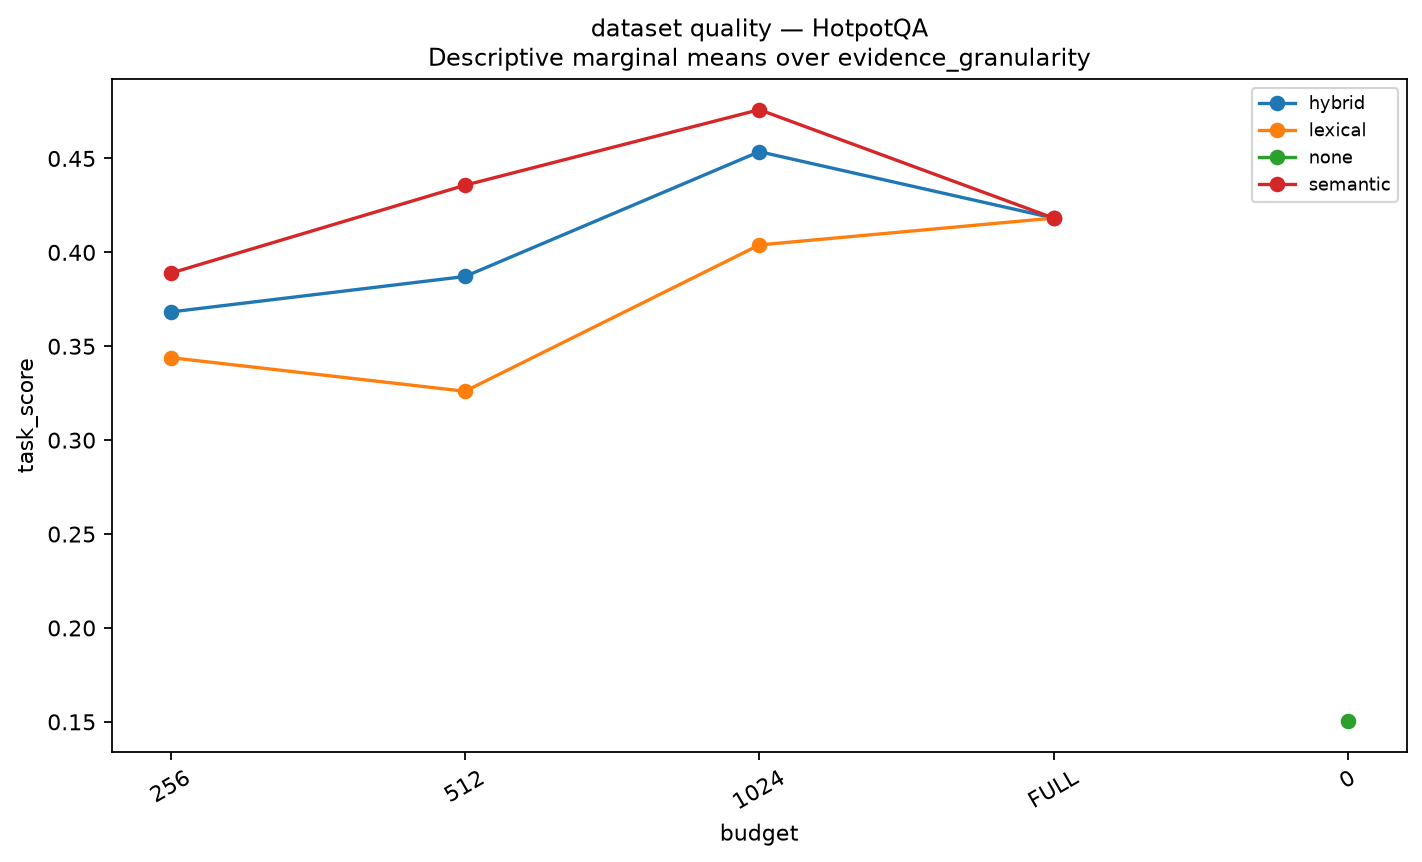

dataset_quality QASPER


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,QASPER,freeform_qa,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,1.918766,20.0,0.230376,1.0,0.158710,0.16,244.90,50,0.594195,512.0,NaN,NaN
1,QASPER,freeform_qa,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.283461,1.0,0.235650,0.16,NaN,50,0.056824,NaN,NaN,NaN
2,QASPER,freeform_qa,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,1.918766,20.0,0.246465,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
3,QASPER,freeform_qa,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,1.918766,20.0,0.246807,1.0,0.168587,0.16,90.96,50,0.400405,512.0,NaN,NaN
4,QASPER,freeform_qa,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.009204,1.0,0.091228,0.16,0.00,50,NaN,0.0,NaN,NaN
5,QASPER,freeform_qa,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,1.918766,20.0,0.240299,1.0,0.243652,0.16,NaN,50,0.058792,NaN,NaN,NaN
6,QASPER,freeform_qa,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,1.918766,20.0,0.263313,1.0,0.211284,0.16,54.54,50,1.048763,256.0,NaN,NaN
7,QASPER,freeform_qa,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,1.918766,20.0,0.280084,1.0,0.189278,0.16,85.16,50,0.443440,512.0,NaN,NaN
8,QASPER,freeform_qa,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,1.918766,20.0,0.252740,1.0,0.209378,0.16,52.60,50,1.029392,256.0,NaN,NaN
9,QASPER,freeform_qa,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,1.918766,20.0,0.229591,1.0,0.091228,0.16,256.00,50,NaN,256.0,NaN,NaN


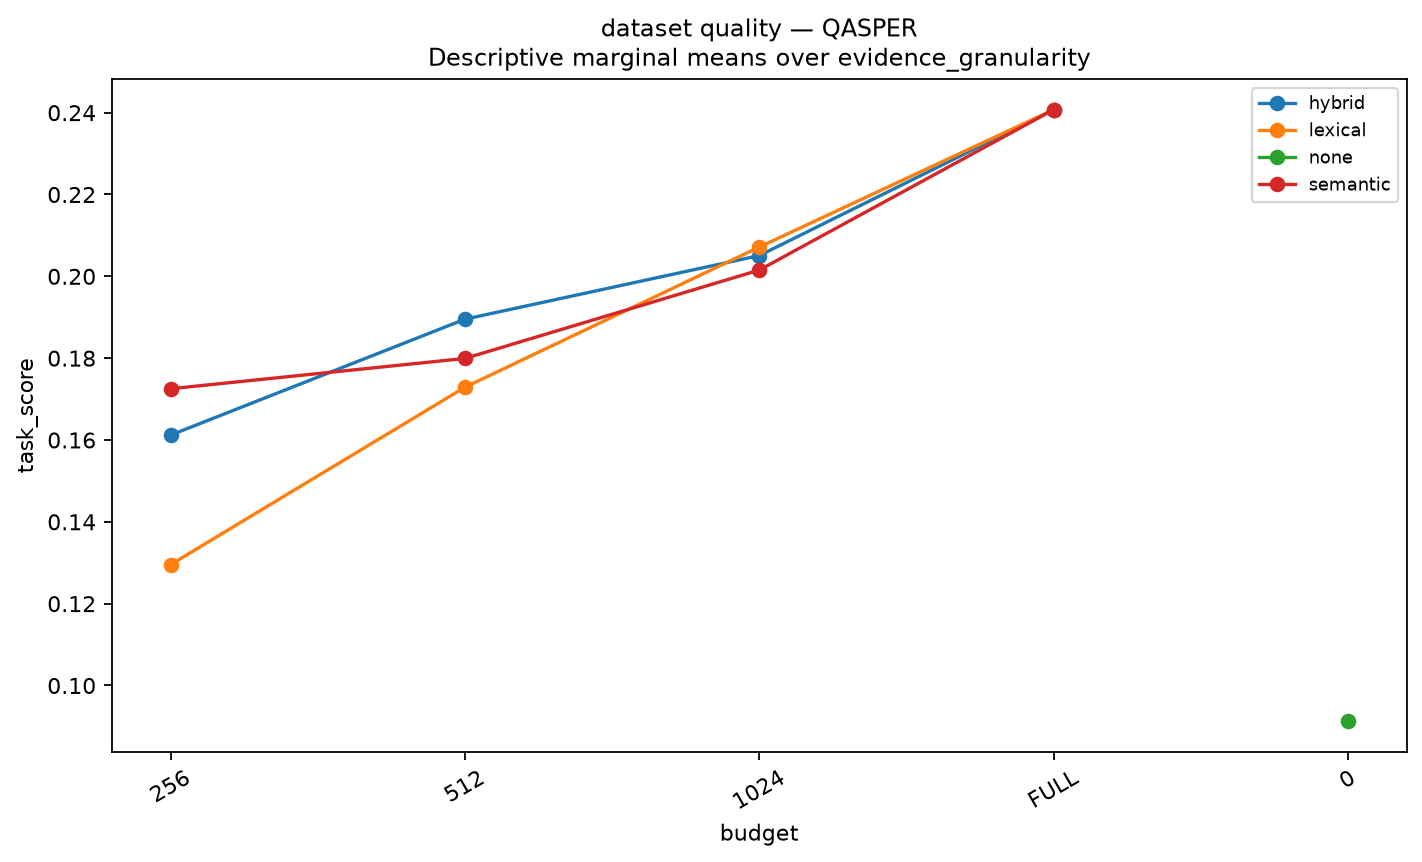

dataset_quality SciFact


,dataset,task_type,action_id,experiment_id,reader,reader_variant,retriever,evidence_granularity,selector,budget,compressor,passage_representation,...,retrieval_latency,retrieval_width,selection_latency,source_support,task_score,unmapped_gold,unused_budget,n_queries,quality_per_1000_tokens,requested_budget_numeric,macro_f1,invalid_label_rate
0,SciFact,verification,015e3dba7459d9196744,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,semantic,512,C0,P0,...,12.952206,20.0,0.528845,1.0,0.66,0.0,274.30,50,2.776609,512.0,0.650292,0.0
1,SciFact,verification,04f870cd6b3587989548,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.600119,1.0,0.68,0.0,NaN,50,0.137550,NaN,0.682828,0.0
2,SciFact,verification,05b2cedae417707e4aeb,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,FULL,C0,P0,...,12.952206,20.0,0.547251,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
3,SciFact,verification,0d19846e7b3ff6023d1a,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,lexical,512,C0,P0,...,12.952206,20.0,0.539233,1.0,0.70,0.0,116.60,50,1.770359,512.0,0.718344,0.0
4,SciFact,verification,0e8bebd7162b7ff88ee7,C,Qwen,PUBLIC_TEXT_READER,SFR,NONE,none,0,C0,P0,...,NaN,20.0,0.143789,1.0,0.36,0.0,0.00,50,NaN,0.0,0.343300,0.0
5,SciFact,verification,0eac66b05d539b0a2522,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,lexical,FULL,C0,P0,...,12.952206,20.0,0.556672,1.0,0.66,0.0,NaN,50,0.133700,NaN,0.661836,0.0
6,SciFact,verification,12bb8307375436eba99c,C,Qwen,PUBLIC_TEXT_READER,SFR,SENTENCE,semantic,256,C0,P0,...,12.952206,20.0,0.552420,1.0,0.68,0.0,68.38,50,3.624347,256.0,0.680824,0.0
7,SciFact,verification,12ff30be690223e91dec,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,512,C0,P0,...,12.952206,20.0,0.563915,1.0,0.62,0.0,119.44,50,1.579376,512.0,0.635587,0.0
8,SciFact,verification,20898211fb3dea90f80d,C,Qwen,PUBLIC_TEXT_READER,SFR,PROPOSITION,semantic,256,C0,P0,...,12.952206,20.0,0.562807,1.0,0.66,0.0,67.46,50,3.500583,256.0,0.664513,0.0
9,SciFact,verification,2277eb14c2313ec6540d,C,Qwen,PUBLIC_TEXT_READER,SFR,PASSAGE,hybrid,256,C0,P0,...,12.952206,20.0,0.527226,1.0,0.36,0.0,236.38,50,18.348624,256.0,0.340182,0.0


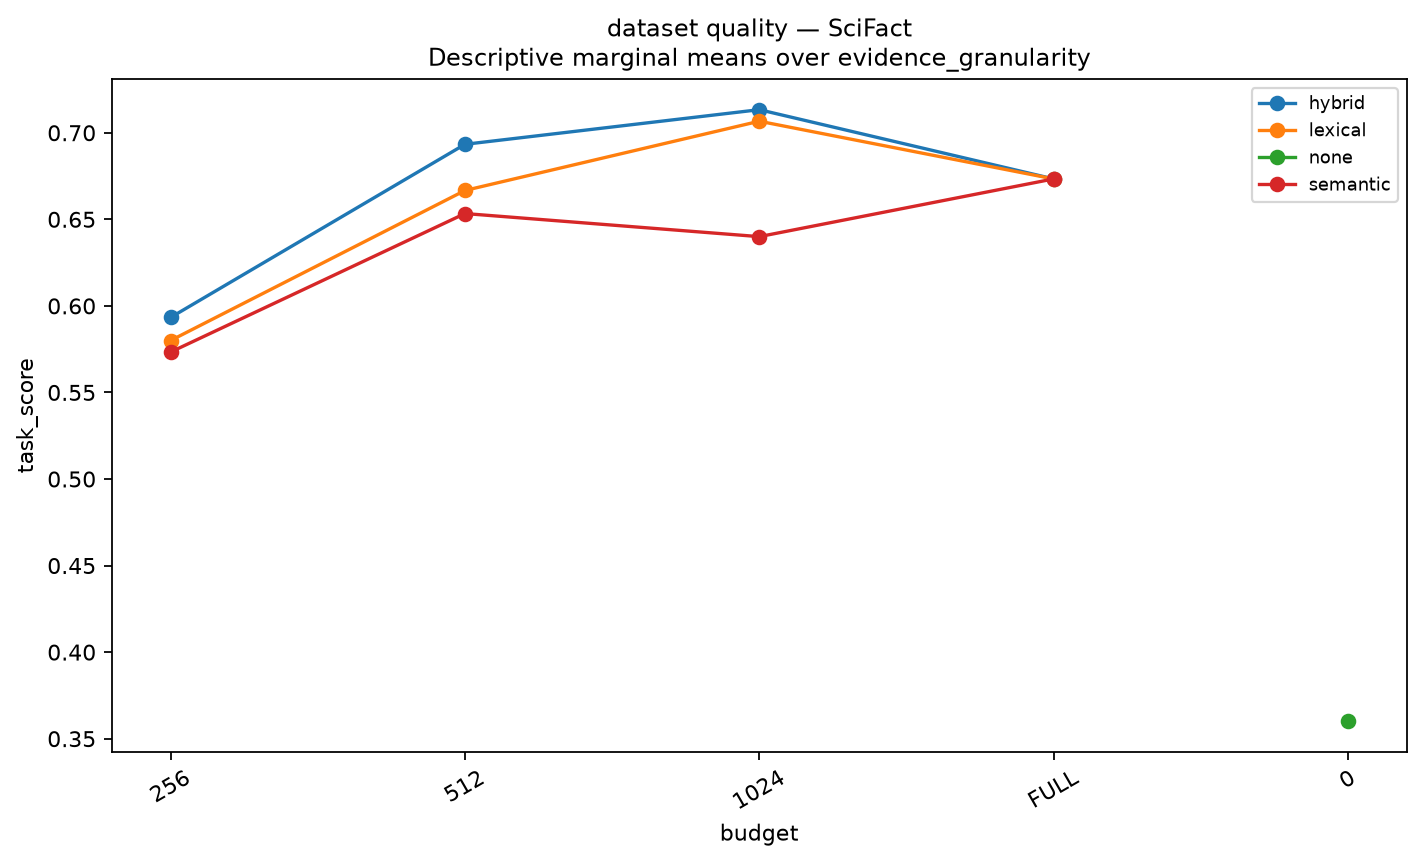

In [11]:
for figure in figures:
    print(figure['name'], figure['dataset'])
    display(pd.read_csv(figure['data']))
    display(Image(filename=figure['png']))
if not figures: print('No completed data for these plots yet; no fabricated values were substituted.')


## Manual review / freeze

After inspecting real completed results, edit the review fields in the first FLAGS cell. Set `REVIEW_PHASE` to this phase, `REVIEWED_CONFIG` to a dictionary, and give a rationale. No winning setting is chosen automatically. Smoke cannot be frozen. If optional conditions remain pending, list them explicitly in `REVIEWED_CONFIG["waive_pending"]`, or qualify them before running.

In [12]:
if REVIEW_PHASE is not None:
    if RUN_SMOKE: raise ValueError('Cannot freeze fabricated smoke output')
    if REVIEW_PHASE != 'C': raise ValueError('Review this notebook phase only')
    display(review(cfg, REVIEW_PHASE, REVIEWED_CONFIG, REVIEW_REASON))
else:
    print('Review not requested. No downstream configuration was selected automatically.')
display(status(cfg))


Review not requested. No downstream configuration was selected automatically.


,phase,notebook,full_status,number_expected,number_completed,result_path,next_action,freeze_exists
0,0,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,150.0,150,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
1,A,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,1350.0,1350,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
2,B,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE,600.0,600,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,True
3,C,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,COMPLETE_ELIGIBLE_PENDING_OPTIONAL,5550.0,5550,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,Review/freeze manually,False
4,D,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
5,E,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
6,F,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
7,G,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
8,H,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
9,I,/home/gunavenkat/Downloads/CS787-RAG-Project/notebooks/week11/week...,NOT_STARTED,NaN,0,/home/gunavenkat/Downloads/CS787-RAG-Project/results/week11/multig...,"Open notebook; inspect safe smoke, then explicitly opt in",False
